# DESN Real-Time ENSO Forecast

Pipeline:
1. **Data loading** — full 1958–2026 dataset; train/val split
2. **Hyperparameter configuration**
3. **Hyperparameter tuning** *(optional, skipped by default)*
4. **Train on 1979–2020**
5. **Member selection + skill comparison** vs XRO on both validation sets
6. **Real-time rolling forecast** from the latest time point

In [6]:
import warnings
warnings.filterwarnings("ignore")
from RCENSO import *
from XRO import *
import numpy as np
import pandas as pd
import reservoirpy as rpy
import xarray as xr
from pathlib import Path
rpy.verbosity(0)
%config InlineBackend.figure_format = 'retina'

# ── Global settings ──────────────────────────────────────────────────────────
SKIP_TUNING = True          # Set False to enable hyperparameter tuning
TUNE_RECENT_WEIGHT = 0.5    # Weight of val(recent) in tuning score; past weight = 1 - this
FORECAST_STEPS = 21         # Real-time forecast horizon (months)
# Set to None to use the last month in the latest oras5_indices_1958-YYYY-MM.nc file.
REALTIME_START = None
PLOT_MODE = 'Nino34'        # Climate mode to plot in the real-time forecast figure
NMEMBERS = 5               # Ensemble members (increase for better estimates)

FORECAST_DIR = Path(r'C:\Users\Win11\Desktop\ENSO_prediction\RC-ENSO-main\forecast')
FORECAST_DIR = Path('')
ORAS5_INDICES_FILE = None  # Set to a specific .nc path to override automatic latest-file selection.

climate_modes = ['Nino34', 'WWV', 'NPMM', 'SPMM', 'IOB', 'TNA', 'ATL3', 'IOD', 'SIOD', 'SASD']

## 1. Data Loading

Three temporal splits:
- **Training**: 1979–2020  
- **Val (past)**: 1958–1978 (pre-training hindcast period)  
- **Val (recent)**: 2021–2026 (out-of-sample)

In [7]:
# Load the latest processed ORAS5 index dataset.
# After Download_data/data_process.ipynb creates a newer oras5_indices_1958-YYYY-MM.nc,
# this cell automatically selects it and initializes the forecast from its last month.
if ORAS5_INDICES_FILE is None:
    candidate_files = sorted(FORECAST_DIR.glob('oras5_indices_1958-*.nc'))
    if not candidate_files:
        raise FileNotFoundError(f'No oras5_indices_1958-*.nc files found in {FORECAST_DIR}')
    ORAS5_INDICES_FILE = candidate_files[-1]
else:
    ORAS5_INDICES_FILE = Path(ORAS5_INDICES_FILE)

ds_full = xr.open_dataset(ORAS5_INDICES_FILE, engine='netcdf4')
ds_full = standardize_time_to_month_start(ds_full)
ds_full = ds_full[['Nino34', 'WWV'] + [v for v in ds_full.data_vars if v not in ('Nino34', 'WWV')]]

if REALTIME_START is None:
    REALTIME_START = pd.Timestamp(ds_full.time.values[-1]).to_period('M').to_timestamp().strftime('%Y-%m-%d')
else:
    # Snap the init month to month-start: ds_full is standardized to month-start, so
    # an exact .sel() needs a month-start label, and pd.date_range(..., freq='MS')
    # must begin on the init month itself (not roll forward to the next month).
    REALTIME_START = pd.Timestamp(REALTIME_START).to_period('M').to_timestamp().strftime('%Y-%m-%d')

print(f'Selected ORAS5 indices file: {ORAS5_INDICES_FILE}')
print(f'Real-time forecast initialization month: {REALTIME_START[:7]}')

# Training dataset (1979-2020) - used to build the full TS matrix
train_ds = ds_full.sel(time=slice('1979-01-01', '2020-12-01'))

# Validation datasets
val_past_ds  = ds_full.sel(time=slice('1958-01-01', '1978-12-01'))
val_recent_ds = ds_full.sel(time=slice('2021-01-01', REALTIME_START))

# TS matrix for the training window only (used to train models)
TS_train = train_ds.to_array().values.T          # (T_train, n_vars)
tl = TS_train.shape[0]                           # training length

# TS matrices for validation windows
TS_past   = val_past_ds.to_array().values.T
TS_recent = val_recent_ds.to_array().values.T

print(f"Training length : {tl} months  ({train_ds.time.values[0]} - {train_ds.time.values[-1]})")
print(f"Val (past)      : {TS_past.shape[0]} months")
print(f"Val (recent)    : {TS_recent.shape[0]} months  ({val_recent_ds.time.values[0]} - {val_recent_ds.time.values[-1]})")


Selected ORAS5 indices file: oras5_indices_1958-2026-07.nc
Real-time forecast initialization month: 2026-07
Training length : 504 months  (1979-01-01T00:00:00.000000000 - 2020-12-01T00:00:00.000000000)
Val (past)      : 252 months
Val (recent)    : 67 months  (2021-01-01T00:00:00.000000000 - 2026-07-01T00:00:00.000000000)


## 2. Hyperparameter Configuration

Default hyperparameters (from the paper).  
The tuning cell below will update these if `SKIP_TUNING = False`.

In [8]:
model_types = [r'DESN($n_l=1$)', r'DESN($n_l=2$)']

hypers = {
    model_types[0]: {
        'units': 20000,
        'lr': 1,
        'sr': 1,
        'rc_connectivity': 0.0,
        'input_connectivity': 0.10,
        'input_scaling': 1,
        'ridge': 5e-6,
        'noise_rc': 0.05,
        'noise_in': 0,
        'output_dim': TS_train.shape[1],
        'seed': None,
        'use_raw_input': True,
        'ip_reservoir': True,
    },
    model_types[1]: {
        'units': [20000, 12000],
        'lr': [1, 1],
        'sr': [1, 1],
        'rc_connectivity': [0, 0],
        'input_connectivity': [0.1, 0.1],
        'input_scaling': [1, 1],
        'ridge': 5e-6,
        'noise_rc': [0.05, 0],
        'noise_in': [0, 0],
        'output_dim': TS_train.shape[1],
        'seed': None,
        'deep': True,
        'deep_ip_list': [True, False],
    },
}

print("Default hyperparameters loaded.")

Default hyperparameters loaded.


## 3. Hyperparameter Tuning *(optional)*

**Strategy**: layer-by-layer, using a **Genetic Algorithm** for fine-tuning around the default values.

- **Layer 1**: GA optimises `input_connectivity` ∈ [0.05, 0.20], `noise_rc` ∈ [0.01, 0.10], `ridge` ∈ [5e-7, 5e-5] (log-scale).
- **Layer 2** (built on best L1): GA optimises `input_connectivity_L2` ∈ [0.05, 0.20] and `units_L2` ∈ [6000, 20000].

GA settings (`GA_POP`, `GA_GENS`, `GA_ELITE`, `GA_MUT_SIGMA`) are tunable at the top of the cell.  
Objective = weighted Nino34 corr at lead 1–12 across both validation sets (`TUNE_RECENT_WEIGHT`).  
Set `SKIP_TUNING = True` (top cell) to skip entirely.

In [9]:
def _val_corr_nino34(trained_models, steps=20, tp_order=2):
    """Weighted mean Nino34 corr (lead 1–12) across both validation sets.
    TUNE_RECENT_WEIGHT controls the weight of val(recent); past weight = 1 - it.
    """
    w_recent = TUNE_RECENT_WEIGHT
    w_past   = 1.0 - w_recent
    scores = []
    for TS_val, w in [(TS_past, w_past), (TS_recent, w_recent)]:
        if w == 0:
            continue
        TP_val = get_RCTP(TS_val, steps=steps, omega=2*np.pi/12, order=tp_order, bias=0)
        Ypred_mean, _ = TPRC_Forecast_Ensemble(
            trained_models, TS_val, TP_test=TP_val, steps=steps, noise_ini=0.0)
        Ytest_arr = np.hstack((TS_val, TP_val[:-steps]))
        R, _ = ndforecast_skill(Ypred_mean, Ytest_arr, showdim=0, ismv3=True, wl=0)
        scores.append(w * np.mean(R[1:13]))
    return sum(scores)


# ── Genetic Algorithm fine-tuning ─────────────────────────────────────────────
# Each gene is a float in [0, 1] that linearly maps to the parameter's search
# range. Ranges are narrow, centred on the default values (±perturbation only).

GA_POP   = 12    # population size (keep small: each eval = 1 training run)
GA_GENS  = 8     # number of generations
GA_ELITE = 2     # elite individuals carried forward unchanged
GA_MUT_SIGMA = 0.15   # Gaussian mutation std (in gene space [0,1])
GA_CROSS_PROB = 0.6   # crossover probability per gene
GA_SEED  = 42


def _decode_l1(gene):
    """Map gene vector [0,1]^3 → (input_connectivity, noise_rc, ridge).
    Ranges: ±50% around defaults, log-scale for ridge.
    """
    ic    = 0.05  + gene[0] * 0.15          # [0.05, 0.20]
    noise = 0.01  + gene[1] * 0.09          # [0.01, 0.10]
    # ridge in log-space: default 5e-6, range [5e-7, 5e-5]
    ridge = 10 ** (-6.3 + gene[2] * 2.0)   # ≈ [5e-7, 5e-5]
    return ic, noise, ridge


def _decode_l2(gene, best_l1):
    """Map gene vector [0,1]^2 → (input_connectivity_l2, units_l2)."""
    ic2 = 0.05 + gene[0] * 0.15            # [0.05, 0.20]
    u2  = int(round((6000 + gene[1] * 14000) / 1000) * 1000)  # [6k,20k] step 1k
    u2  = min(u2, 20000)
    return ic2, u2


def _ga_evolve(n_genes, decode_fn, eval_fn, pop_size, n_gens,
               n_elite, mut_sigma, cross_prob, rng, label):
    """Minimalist GA: real-valued genes in [0,1]^n_genes.
    Uses tournament selection, uniform crossover, Gaussian mutation.
    Returns best_gene, best_score.
    """
    pop = rng.uniform(0, 1, size=(pop_size, n_genes))
    fitness = np.full(pop_size, -np.inf)

    for gen in range(n_gens):
        # Evaluate unevaluated individuals
        for i in range(pop_size):
            if fitness[i] == -np.inf:
                fitness[i] = eval_fn(pop[i])

        best_idx = np.argmax(fitness)
        print(f"  [{label}] Gen {gen+1}/{n_gens}  "
              f"best={fitness[best_idx]:.4f}  params={decode_fn(pop[best_idx])}")

        if gen == n_gens - 1:
            break

        # Sort by fitness descending
        order = np.argsort(fitness)[::-1]
        new_pop = pop[order[:n_elite]].copy()  # elites
        new_fit = fitness[order[:n_elite]].copy()

        # Fill rest of population via tournament + crossover + mutation
        while len(new_pop) < pop_size:
            # Tournament selection (size 3)
            def tournament():
                idx = rng.choice(pop_size, size=3, replace=False)
                return pop[idx[np.argmax(fitness[idx])]].copy()

            p1, p2 = tournament(), tournament()
            # Uniform crossover
            mask = rng.uniform(size=n_genes) < cross_prob
            child = np.where(mask, p1, p2)
            # Gaussian mutation
            child += rng.normal(0, mut_sigma, size=n_genes)
            child = np.clip(child, 0, 1)
            new_pop = np.vstack([new_pop, child[None]])
            new_fit = np.append(new_fit, -np.inf)  # will be evaluated next gen

        pop = new_pop
        fitness = new_fit

    best_idx = np.argmax(fitness)
    return pop[best_idx], fitness[best_idx]


if not SKIP_TUNING:
    rng = np.random.default_rng(GA_SEED)

    # ── Layer 1 GA ────────────────────────────────────────────────────────────
    print("=" * 60)
    print(f"LAYER 1 GA TUNING  "
          f"(recent_w={TUNE_RECENT_WEIGHT}, pop={GA_POP}, gens={GA_GENS})")
    print("=" * 60)

    def _eval_l1(gene):
        ic, noise, ridge = _decode_l1(gene)
        h = {**hypers[model_types[0]],
             'input_connectivity': ic, 'noise_rc': noise, 'ridge': ridge}
        models_tmp, _ = TPRC_Train_Ensemble(TS_train, tl, dl=0, hypers=h, nmember=1)
        return _val_corr_nino34(models_tmp)

    best_gene_l1, best_score_l1 = _ga_evolve(
        n_genes=3, decode_fn=_decode_l1, eval_fn=_eval_l1,
        pop_size=GA_POP, n_gens=GA_GENS, n_elite=GA_ELITE,
        mut_sigma=GA_MUT_SIGMA, cross_prob=GA_CROSS_PROB,
        rng=rng, label='L1')

    ic_best, noise_best, ridge_best = _decode_l1(best_gene_l1)
    best_l1_params = {'input_connectivity': ic_best,
                      'noise_rc': noise_best, 'ridge': ridge_best}
    hypers[model_types[0]].update(best_l1_params)
    print(f"\nBest L1: ic={ic_best:.4f}, noise={noise_best:.4f}, "
          f"ridge={ridge_best:.2e}  (score={best_score_l1:.4f})")

    # ── Layer 2 GA ────────────────────────────────────────────────────────────
    print("\n" + "=" * 60)
    print(f"LAYER 2 GA TUNING  (pop={GA_POP}, gens={GA_GENS})")
    print("=" * 60)

    def _eval_l2(gene):
        ic2, u2 = _decode_l2(gene, best_l1_params)
        h2 = {**hypers[model_types[1]],
              'input_connectivity': [ic_best, ic2],
              'noise_rc': [noise_best, 0],
              'ridge': ridge_best,
              'units': [20000, u2]}
        models_tmp2, _ = TPRC_Train_Ensemble(TS_train, tl, dl=0, hypers=h2, nmember=1)
        return _val_corr_nino34(models_tmp2)

    best_gene_l2, best_score_l2 = _ga_evolve(
        n_genes=2, decode_fn=lambda g: _decode_l2(g, best_l1_params),
        eval_fn=_eval_l2,
        pop_size=GA_POP, n_gens=GA_GENS, n_elite=GA_ELITE,
        mut_sigma=GA_MUT_SIGMA, cross_prob=GA_CROSS_PROB,
        rng=rng, label='L2')

    ic2_best, u2_best = _decode_l2(best_gene_l2, best_l1_params)
    hypers[model_types[1]].update({
        'input_connectivity': [ic_best, ic2_best],
        'noise_rc': [noise_best, 0],
        'ridge': ridge_best,
        'units': [20000, u2_best],
    })
    print(f"\nBest L2: ic2={ic2_best:.4f}, units2={u2_best}  (score={best_score_l2:.4f})")

else:
    print("Hyperparameter tuning skipped (SKIP_TUNING=True).")

Hyperparameter tuning skipped (SKIP_TUNING=True).


## 4. Train DESN Ensemble on 1979–2020

In [10]:
trained_models = {}   # {model_type: list_of_esns}
TP_train = {}         # {model_type: TP array}

for mt in model_types:
    print(f"Training {mt} …")
    models, tp = TPRC_Train_Ensemble(
        TS_train, tl, dl=0, hypers=hypers[mt], nmember=NMEMBERS)
    trained_models[mt] = models
    TP_train[mt] = tp
    print(f"  Done. ({NMEMBERS} member(s))")

Training DESN($n_l=1$) …


Training ensemble members: 100%|██████████| 5/5 [04:29<00:00, 53.87s/it]


  Done. (5 member(s))
Training DESN($n_l=2$) …


Training ensemble members:   0%|          | 0/5 [00:00<?, ?it/s]

Layer 1: units=20000, sr=1, lr=1, ip_reservoir=True
Layer 2: units=12000, sr=1, lr=1, ip_reservoir=False


...

Layer 1: units=20000, sr=1, lr=1, ip_reservoir=True
Layer 2: units=12000, sr=1, lr=1, ip_reservoir=False


Training ensemble members:  80%|████████  | 4/5 [11:01<02:33, 153.42s/it]

Layer 1: units=20000, sr=1, lr=1, ip_reservoir=True
Layer 2: units=12000, sr=1, lr=1, ip_reservoir=False


Training ensemble members: 100%|██████████| 5/5 [13:23<00:00, 160.72s/it]

  Done. (5 member(s))


## 5. Validation, Member Selection & Skill Comparison

- **Member selection**: from all `NMEMBERS × 2` trained models (both architectures), greedily pick the best `N_SELECT` whose *joint* ensemble mean maximises the weighted validation score.
- **Skill plot**: selected DESN ensemble vs XRO baseline on both validation sets.

In [11]:
from itertools import combinations
from math import comb

KEEP_SELECT = 4          # minimum ensemble size
KEEP_MAX    = 10         # maximum ensemble size (full pool)
FORECAST_STEPS_SKILL = 16   # lead times for skill evaluation


# ── Gather predictions from all members on both validation sets ─────────────
all_member_preds = {}    # {val_label: list of (T, n_vars+tp, steps) arrays}
Ytest_val = {}

for val_label, TS_val in [('past', TS_past), ('recent', TS_recent)]:
    TP_val = get_RCTP(TS_val, steps=FORECAST_STEPS_SKILL,
                      omega=2*np.pi/12, order=2, bias=0)
    Ytest_val[val_label] = np.hstack((TS_val, TP_val[:-FORECAST_STEPS_SKILL]))
    
    preds_list = []
    for mt in model_types:
        _, preds_mt = TPRC_Forecast_Ensemble(
            trained_models[mt], TS_val, TP_test=TP_val,
            steps=FORECAST_STEPS_SKILL, noise_ini=0.0)
        for m in range(preds_mt.shape[0]):
            preds_list.append(preds_mt[m])
    all_member_preds[val_label] = preds_list



Forecasting with ensemble:   0%|          | 0/5 [00:00<?, ?it/s]

Forecasting with ensemble: 100%|██████████| 5/5 [01:44<00:00, 20.85s/it]


Pool: 10 members | Exhaustive search: 848 combinations (k=4..10)
  k= 4  best_corr=0.7759  members=(5, 6, 7, 9)  (DESN(n_l=2)#0, DESN(n_l=2)#1, DESN(n_l=2)#2, DESN(n_l=2)#4)
  k= 5  best_corr=0.7742  members=(5, 6, 7, 8, 9)  (DESN(n_l=2)#0, DESN(n_l=2)#1, DESN(n_l=2)#2, DESN(n_l=2)#3, DESN(n_l=2)#4)
  k= 6  best_corr=0.7667  members=(4, 5, 6, 7, 8, 9)  (DESN(n_l=1)#4, DESN(n_l=2)#0, DESN(n_l=2)#1, DESN(n_l=2)#2, DESN(n_l=2)#3, DESN(n_l=2)#4)
  k= 7  best_corr=0.7592  members=(1, 4, 5, 6, 7, 8, 9)  (DESN(n_l=1)#1, DESN(n_l=1)#4, DESN(n_l=2)#0, DESN(n_l=2)#1, DESN(n_l=2)#2, DESN(n_l=2)#3, DESN(n_l=2)#4)
  k= 8  best_corr=0.7498  members=(1, 3, 4, 5, 6, 7, 8, 9)  (DESN(n_l=1)#1, DESN(n_l=1)#3, DESN(n_l=1)#4, DESN(n_l=2)#0, DESN(n_l=2)#1, DESN(n_l=2)#2, DESN(n_l=2)#3, DESN(n_l=2)#4)
  k= 9  best_corr=0.7414  members=(0, 1, 3, 4, 5, 6, 7, 8, 9)  (DESN(n_l=1)#0, DESN(n_l=1)#1, DESN(n_l=1)#3, DESN(n_l=1)#4, DESN(n_l=2)#0, DESN(n_l=2)#1, DESN(n_l=2)#2, DESN(n_l=2)#3, DESN(n_l=2)#4)
  k=10  bes

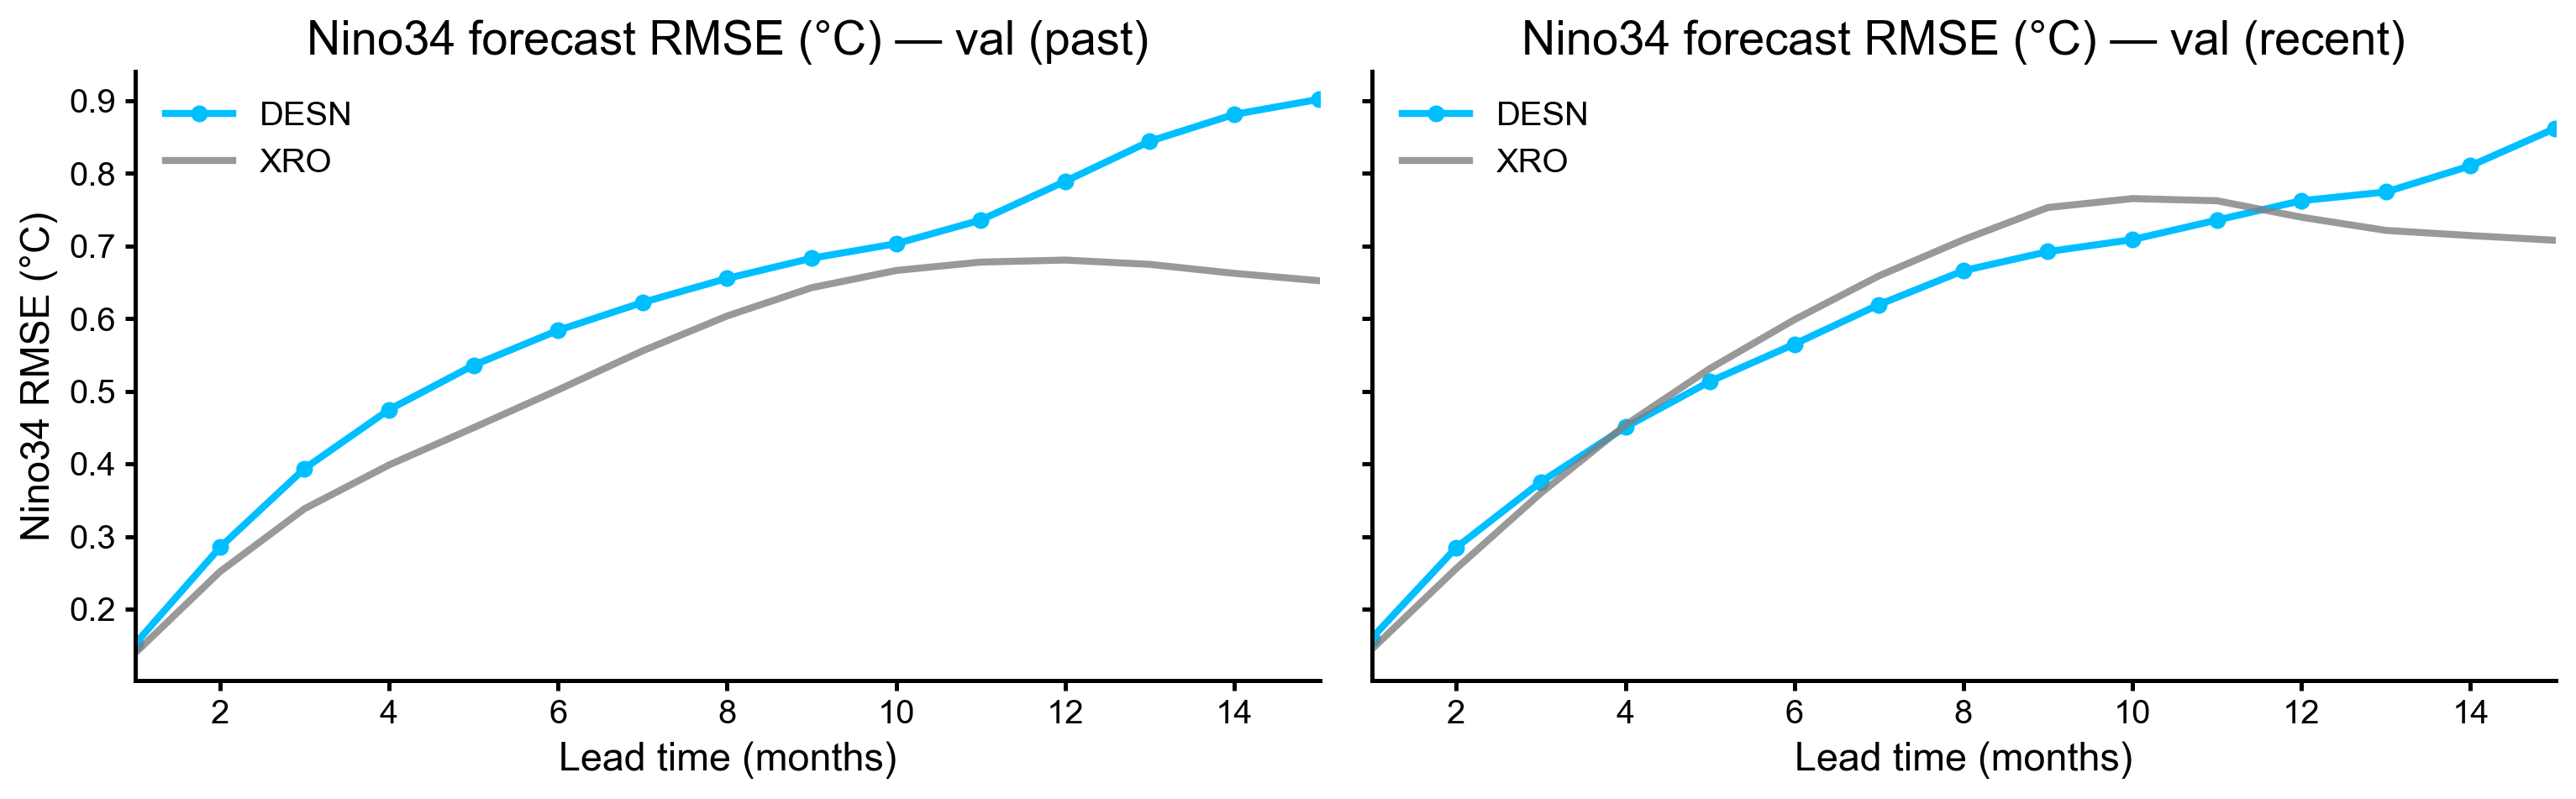

In [12]:
SELECT_METRIC = 'corr'   # member-selection objective: 'corr' (maximise Pearson
                         # correlation) or 'rmse' (minimise RMSE)
n_pool = len(all_member_preds['past'])
total = sum(comb(n_pool, k) for k in range(KEEP_SELECT, KEEP_MAX + 1))
print(f"Pool: {n_pool} members | Exhaustive search: {total} combinations (k={KEEP_SELECT}..{KEEP_MAX})")

# ── Scoring function for any subset ─────────────────────────────────────────
# Always returns a value to MAXIMISE: correlation directly, or negative RMSE
# (so that a smaller RMSE yields a higher score).
def score_subset(indices):
    score = 0.0
    for val_label, w in [('past', 1 - TUNE_RECENT_WEIGHT), ('recent', TUNE_RECENT_WEIGHT)]:
        if w == 0:
            continue
        ens = np.mean([all_member_preds[val_label][i] for i in indices], axis=0)
        R, RMSE = ndforecast_skill(ens, Ytest_val[val_label], showdim=0, ismv3=True, wl=0)
        if SELECT_METRIC == 'rmse':
            score += w * (-np.mean(RMSE[1:13]))
        else:
            score += w * np.mean(R[1:13])
    return score

# ── Exhaustive search: C(n,4) to C(n,10) ────────────────────────────────────
best_score = -np.inf
best_combo = None
best_size  = None

for k in range(KEEP_SELECT, KEEP_MAX + 1):
    best_k, score_k = None, -np.inf
    for combo in combinations(range(n_pool), k):
        s = score_subset(list(combo))
        if s > score_k:
            score_k, best_k = s, combo
    
    # print per-size summary (RMSE objective is reported back as positive RMSE)
    show_k = -score_k if SELECT_METRIC == 'rmse' else score_k
    names = [f"{model_types[i//max(1,NMEMBERS)].replace('$','')}#{i%max(1,NMEMBERS)}" for i in best_k]
    print(f"  k={k:2d}  best_{SELECT_METRIC}={show_k:.4f}  members={best_k}  ({', '.join(names)})")
    
    if score_k > best_score:
        best_score, best_combo, best_size = score_k, best_k, k

selected = list(best_combo)
show_best = -best_score if SELECT_METRIC == 'rmse' else best_score
print(f"\n>> Global best ({SELECT_METRIC}): size={best_size}, "
      f"score={show_best:.4f}, members={selected}")

# ── Build selected model list (compatible with downstream code) ─────────────
selected_models = []
for idx in selected:
    mt = model_types[idx // max(1, NMEMBERS)]
    selected_models.append({
        'arch': mt,
        'member': idx % max(1, NMEMBERS),
        'esn': trained_models[mt][idx % max(1, NMEMBERS)]
    })

# ── Evaluate selected ensemble vs XRO baseline ────────────────────────────────
# corr_*  : Pearson correlation vs lead;  rmse_* : RMSE vs lead (2nd output of
# ndforecast_skill). rmse_desn is reused downstream as the real-time forecast
# error bar (lead 1 = rolling 1st month, etc.).
corr_desn, corr_xro = {}, {}
rmse_desn, rmse_xro = {}, {}

XROac2 = XRO(ncycle=12, ac_order=2)
XROac2_fit = XROac2.fit_matrix(train_ds, maskb=['Nino34', 'IOD'], maskNT=['TH'])

for val_label, TS_val, val_ds in [('past', TS_past, val_past_ds),
                                  ('recent', TS_recent, val_recent_ds)]:
    # DESN ensemble mean
    ens = np.mean([all_member_preds[val_label][i] for i in selected], axis=0)
    R_desn, RMSE_desn = ndforecast_skill(ens, Ytest_val[val_label], showdim=0, ismv3=True, wl=0)
    corr_desn[val_label] = R_desn
    rmse_desn[val_label] = RMSE_desn

    # XRO baseline
    xro = XROac2.reforecast(fit_ds=XROac2_fit, init_ds=val_ds,
                            n_month=FORECAST_STEPS_SKILL - 1, ncopy=1, noise_type='zero')
    Ypred = xro.to_array().values.transpose(1, 0, 2)
    n_steps = Ypred.shape[2]
    TP_xro = get_RCTP(TS_val, steps=n_steps, omega=2*np.pi/12, order=2, bias=0)
    Ytest_xro = np.hstack((TS_val, TP_xro[:-n_steps]))
    R_xro, RMSE_xro = ndforecast_skill(Ypred, Ytest_xro, showdim=0, ismv3=True, wl=0)
    corr_xro[val_label] = R_xro
    rmse_xro[val_label] = RMSE_xro

    print(f"{val_label:8s}  DESN corr@6={R_desn[6]:.3f} rmse@6={RMSE_desn[6]:.3f}  |  "
          f"XRO corr@6={R_xro[6]:.3f} rmse@6={RMSE_xro[6]:.3f}")

# ── Plots: correlation and RMSE, each past | recent as left/right subplots ───

leads = np.arange(1, FORECAST_STEPS_SKILL)   # skip lead 0 (corr=1, RMSE=0 by def.)


def _plot_skill_pair(skill_desn, skill_xro, skill_name, ylim=None, hline=None):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), dpi=120, sharey=True)
    for ax, val_label in zip(axes, ['past', 'recent']):
        ax.plot(leads, skill_desn[val_label][1:], color='deepskyblue', marker='o',
                markersize=5, linewidth=2.5, label='DESN')
        ax.plot(leads, skill_xro[val_label][1:], color='gray', linewidth=2.5,
                alpha=0.8, label='XRO')
        if hline is not None:
            ax.axhline(hline, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
        ax.set_title(f'{PLOT_MODE} forecast {skill_name} — val ({val_label})')
        ax.set_xlabel('Lead time (months)')
        ax.set_xlim(1, FORECAST_STEPS_SKILL - 0.99)
        if ylim is not None:
            ax.set_ylim(*ylim)
        ax.legend(frameon=False)
        for spine in ['top', 'right']:
            ax.spines[spine].set_visible(False)
    axes[0].set_ylabel(f'{PLOT_MODE} {skill_name}')
    plt.tight_layout()
    plt.show()


# _plot_skill_pair(corr_desn, corr_xro, 'Correlation', ylim=(0.0, 1.0), hline=0.5)
_plot_skill_pair(rmse_desn, rmse_xro, 'RMSE (°C)')


In [13]:
# RMSE peak values for the bottom-row subplots above (same lead range as plotted)
print('\n=== RMSE peak values for the bottom-row subplots ===')
for val_label in ['past', 'recent']:
    print(f'\n{val_label} validation')
    for model_name, rmse_dict in [('DESN', rmse_desn), ('XRO', rmse_xro)]:
        rmse_curve = np.asarray(rmse_dict[val_label])[1:]
        peak_i = int(np.nanargmax(rmse_curve))
        peak_lead = int(leads[peak_i])
        peak_rmse = float(rmse_curve[peak_i])
        print(f'  {model_name:4s}: peak RMSE = {peak_rmse:.3f} degC at lead {peak_lead}')



=== RMSE peak values for the bottom-row subplots ===

past validation
  DESN: peak RMSE = 0.902 degC at lead 15
  XRO : peak RMSE = 0.681 degC at lead 12

recent validation
  DESN: peak RMSE = 0.862 degC at lead 15
  XRO : peak RMSE = 0.765 degC at lead 10


## 6. Real-Time Rolling Forecast from Latest Time Point

In [14]:
def realtime_forecast(models, x0, TP_rt, t0, forecast_steps):
    """
    Iterative multi-step real-time forecast for a given model ensemble.

    Parameters
    ----------
    models : list of dict
        Selected model list, each item must contain key 'esn' with a .run() method.
        e.g. [{'arch': 'DESN$', 'member': 0, 'esn': esn_obj}, ...]
    x0 : ndarray, shape (n_vars,)
        Latest observed state (initial condition).
    TP_rt : ndarray, shape (T_full + forecast_steps, n_tp)
        RCTP (known external forcing) covering history + forecast leads.
    t0 : int
        Time index of the last observed month in TP_rt (i.e. len(history)).
    forecast_steps : int
        Number of lead months to predict.

    Returns
    -------
    member_preds : ndarray, shape (n_models, forecast_steps + 1, n_vars)
        Individual forecasts. Lead 0 is the observed x0; leads 1..forecast_steps
        are model predictions.
    ens_mean : ndarray, shape (forecast_steps + 1, n_vars)
        Ensemble mean across all models.
    ens_std : ndarray, shape (forecast_steps + 1, n_vars)
        Ensemble standard deviation.
    """
    member_preds = []

    for model in models:
        esn = model['esn']
        fcst = [x0.copy()]                     # lead 0 = observation

        # Reservoir input: [state, RCTP] at t0-1 (last observed time)
        rctp = TP_rt[t0 - 1, :].reshape(1, -1)
        x = np.hstack((x0.reshape(1, -1), rctp))

        for j in range(1, forecast_steps + 1):
            y = esn.run(x)                     # (1, n_vars)
            fcst.append(y[0].copy())

            # Advance to next lead's known RCTP
            rctp = TP_rt[t0 - 1 + j, :].reshape(1, -1)
            x = np.hstack((y, rctp))

        member_preds.append(np.array(fcst))    # (forecast_steps+1, n_vars)

    member_preds = np.array(member_preds)      # (n_models, forecast_steps+1, n_vars)
    ens_mean = member_preds.mean(axis=0)
    ens_std  = member_preds.std(axis=0)

    return member_preds, ens_mean, ens_std

In [15]:
# --- prepare history & forcing ------------------------------------------------
ds_full_to_latest = ds_full.sel(time=slice('1979-01-01', REALTIME_START))
TS_full = ds_full_to_latest.to_array().values.T          # (T, n_vars)
t0      = TS_full.shape[0]
x0      = TS_full[-1, :].copy()                        # (n_vars,)

TP_rt = get_RCTP(TS_full, steps=FORECAST_STEPS,
                 omega=2*np.pi/12, order=2, bias=0)    # (T+steps, n_tp)

# --- call the unified forecast function ----------------------------------------
member_preds, rt_mean, rt_std = realtime_forecast(
    selected_models, x0, TP_rt, t0, FORECAST_STEPS
)

start_pd = pd.Timestamp(REALTIME_START)
forecast_times = pd.date_range(start_pd, periods=FORECAST_STEPS + 1, freq='MS')
print(f'forecast from {forecast_times[0]} to {forecast_times[-1]}')

forecast from 2026-07-01 00:00:00 to 2028-04-01 00:00:00


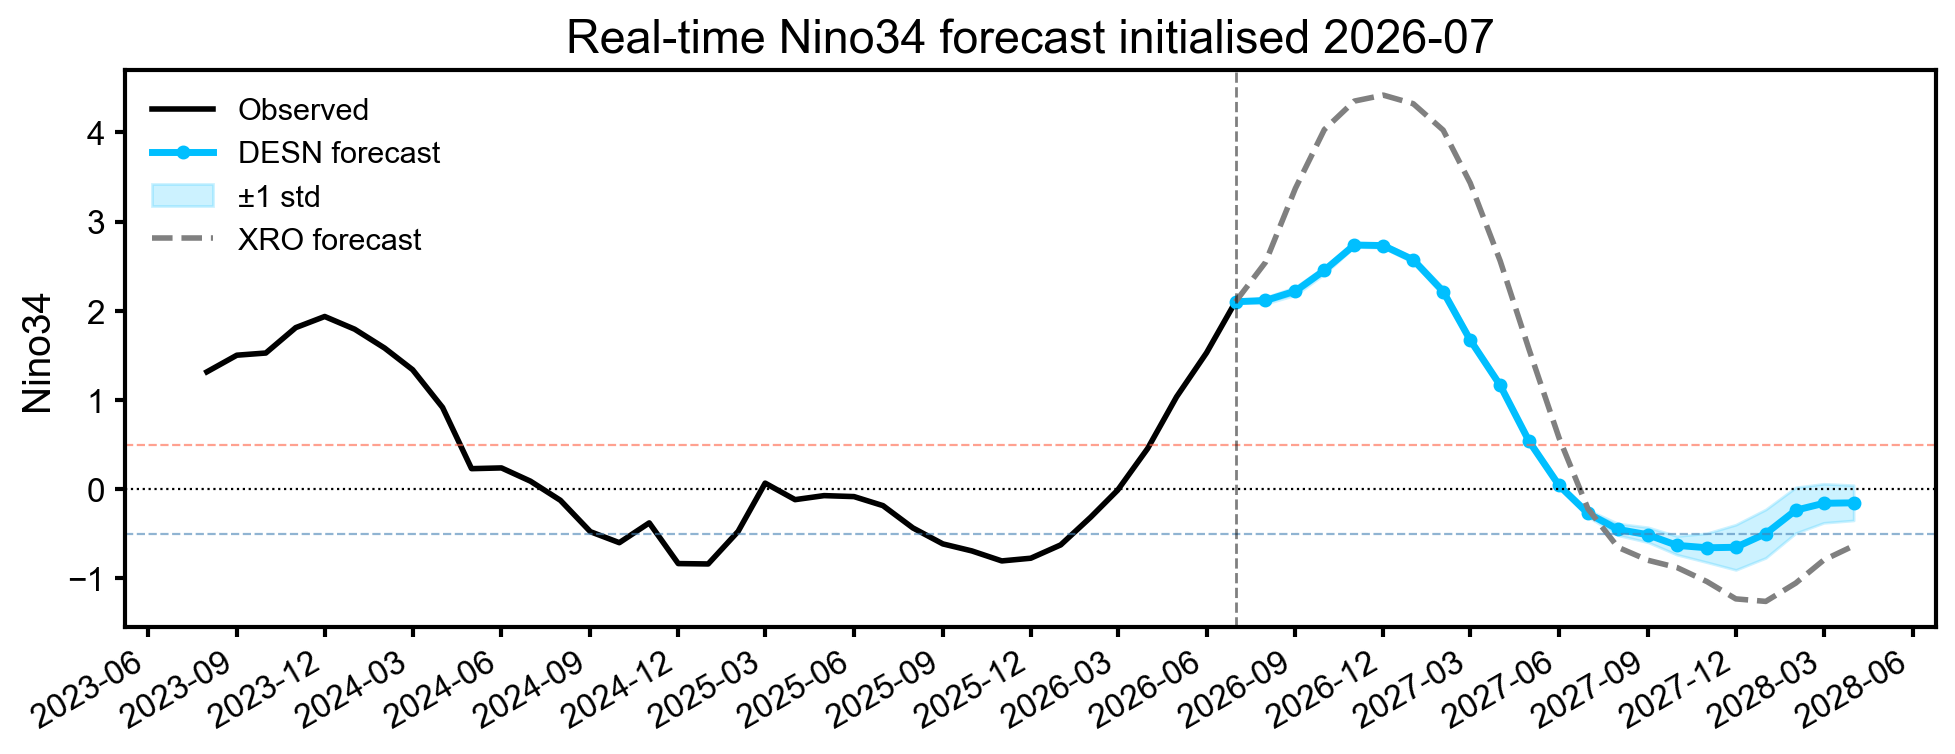

In [16]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ── Resolve mode index from the dataset itself ─────────────────────────────────
mode_idx = list(ds_full.data_vars).index(PLOT_MODE)

# ── Historical observed (last 36 months before forecast) ─────────────────────
n_hist = 36
time_full = ds_full_to_latest.time.values
hist_times = pd.DatetimeIndex([pd.Timestamp(str(t)[:10]) for t in time_full[-n_hist:]])
hist_vals  = TS_full[-n_hist:, mode_idx]

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))

# Observed history
ax.plot(hist_times, hist_vals, color='black', linewidth=2, label='Observed')

# DESN ensemble mean forecast (lead 0 = obs, leads 1..N = forecast)
ax.plot(forecast_times, rt_mean[:, mode_idx],
        color='deepskyblue', linewidth=2.5, marker='o', markersize=4,
        label='DESN forecast')

# Ensemble spread (±1 std) — check actual ensemble size, not raw NMEMBERS
if member_preds.shape[0] > 1:
    ax.fill_between(
        forecast_times,
        rt_mean[:, mode_idx] - rt_std[:, mode_idx],
        rt_mean[:, mode_idx] + rt_std[:, mode_idx],
        color='deepskyblue', alpha=0.2, label='±1 std')

# XRO real-time forecast
ds_init_rt = ds_full.sel(time=REALTIME_START).expand_dims('time')
try:
    xro_rt_fcst = XROac2.reforecast(
        fit_ds=XROac2_fit, init_ds=ds_init_rt,
        n_month=FORECAST_STEPS, ncopy=1, noise_type='zero')
    xro_rt_vals = xro_rt_fcst[PLOT_MODE].values.squeeze()  # (steps,)
    xro_times = pd.date_range(start_pd, periods=len(xro_rt_vals), freq='MS')
    ax.plot(xro_times, xro_rt_vals,
            color='gray', linewidth=2, linestyle='--', label='XRO forecast')
except Exception as e:
    print(f"XRO real-time forecast skipped: {e}")

# ── Decorations ─────────────────────────────────────────────────────────────
ax.axhline(0, color='black', linewidth=0.8, linestyle=':')
ax.axhline(0.5,  color='tomato',     linewidth=0.8, linestyle='--', alpha=0.6)
ax.axhline(-0.5, color='steelblue',  linewidth=0.8, linestyle='--', alpha=0.6)
ax.axvline(start_pd, color='black', linewidth=1, linestyle='--', alpha=0.5)

ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha='right')

ax.set_ylabel(PLOT_MODE)
ax.set_title(f'Real-time {PLOT_MODE} forecast initialised {REALTIME_START[:7]}')
ax.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.show()

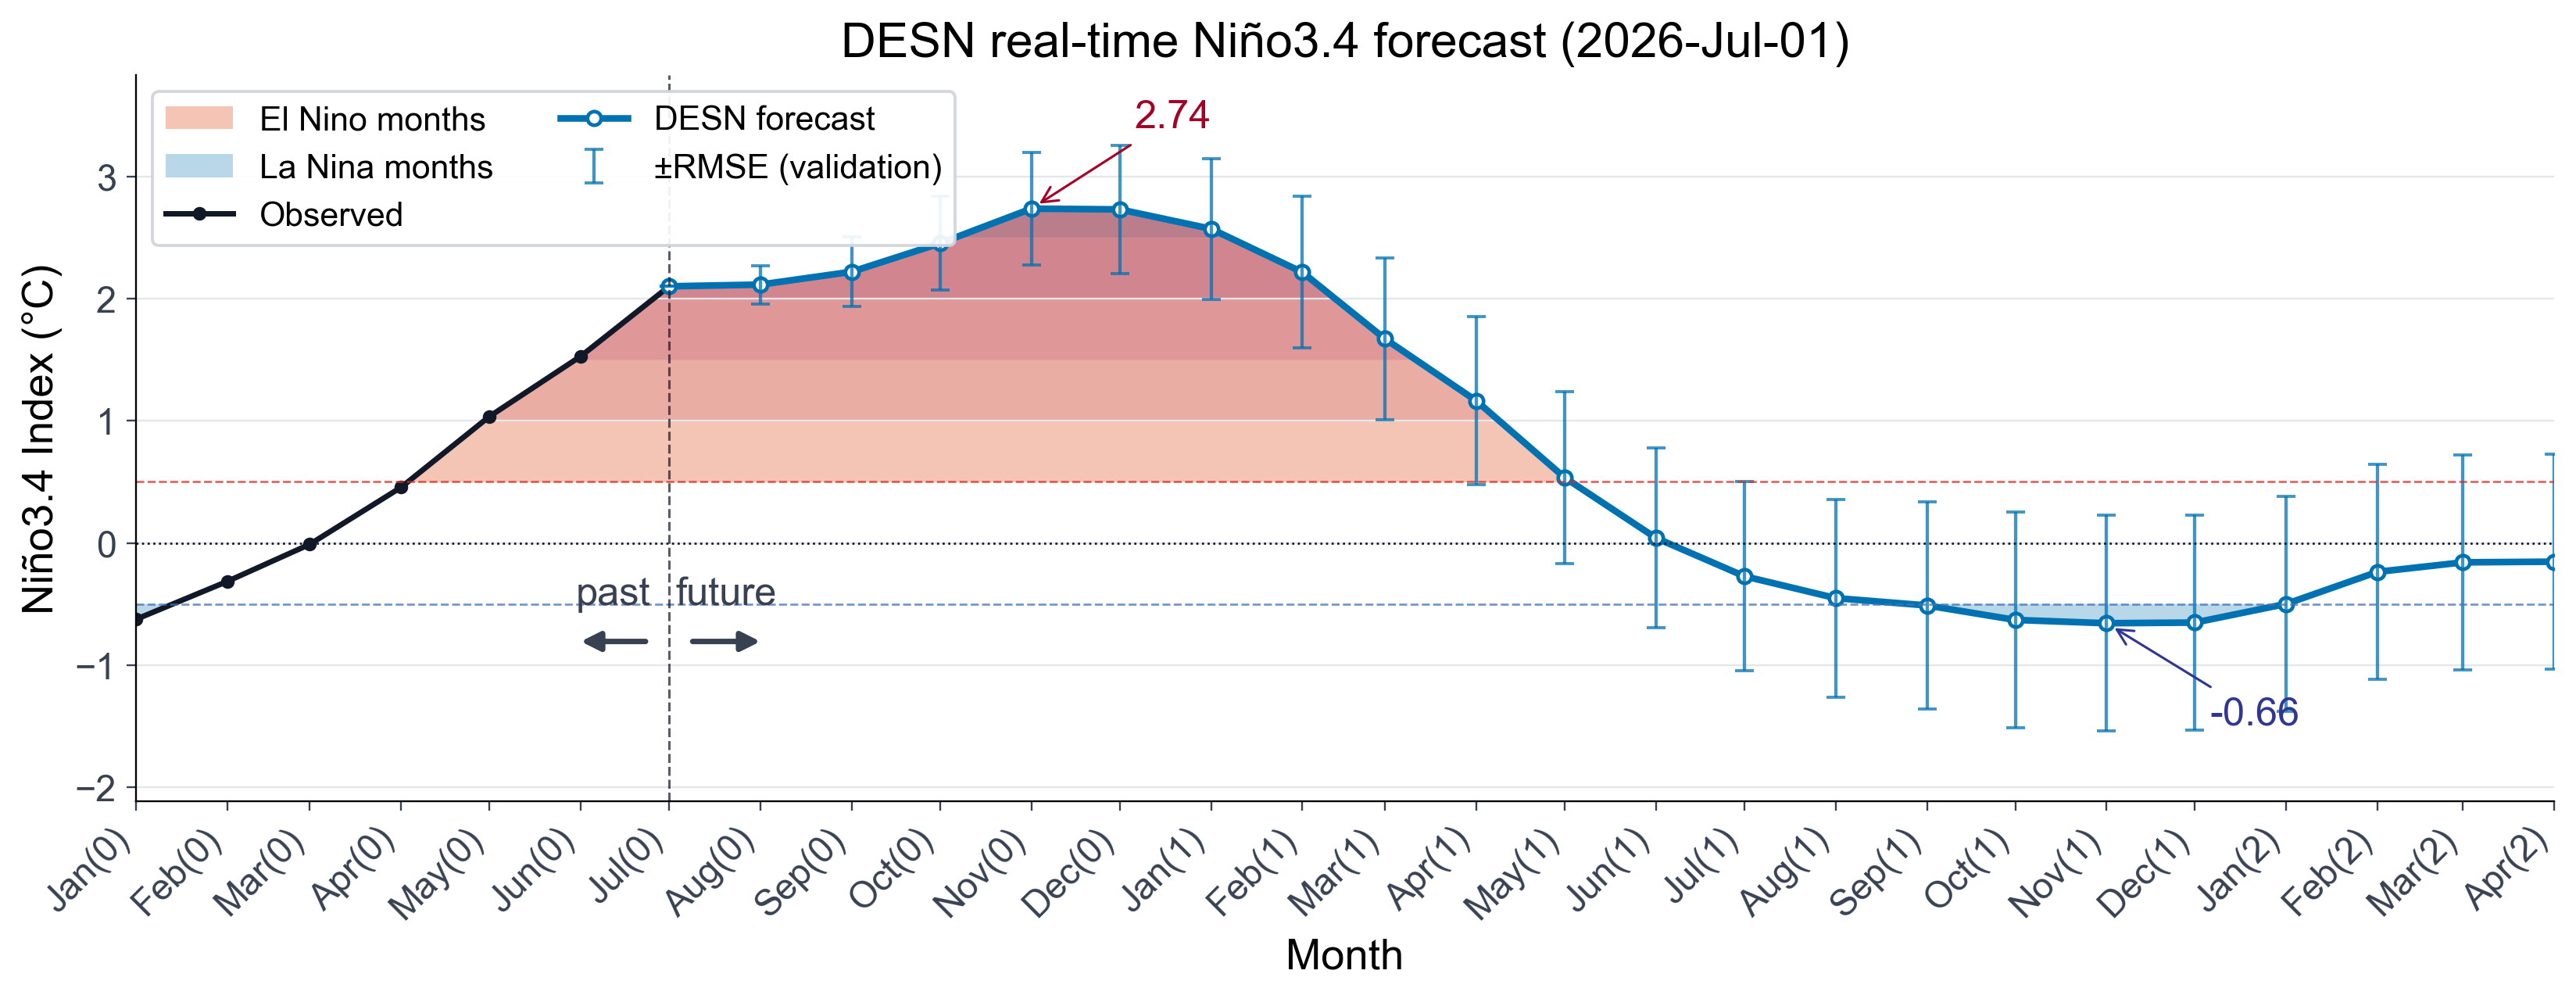

In [17]:
# ── Report-style forecast figure (matching forecast_real_time_simple.ipynb) ──
# Same styling as the simple notebook, plus error bars on each forecast point
# equal to the validation RMSE at that lead time (lead 1 = rolling 1st month,
# etc.). rmse_desn was computed in the skill cell above; here it is averaged
# 50/50 over the past & recent validation sets.
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

MONTH_ABBR = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
              'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
mode_names = list(ds_full.data_vars)
PLOT_HISTORY_MONTHS = 6   # months of observed history shown before initialisation


def to_month_start(ts):
    return pd.Timestamp(ts).to_period('M').to_timestamp()


# Combined (50/50 mean of past & recent) validation RMSE → forecast error bar.
# To use recent only instead: rmse_combined = rmse_desn['recent'].
rmse_combined = 0.5 * (rmse_desn['past'] + rmse_desn['recent'])

# Map each forecast lead (0..FORECAST_STEPS) onto a validation RMSE. Leads beyond
# the validation horizon hold the last available (largest-lead) RMSE.
forecast_yerr = np.array([rmse_combined[min(j, len(rmse_combined) - 1)]
                          for j in range(len(forecast_times))])


# ── Styled forecast helpers (ported from forecast_real_time_simple.ipynb) ────
def month_year_label(ts, base_month):
    return f"{MONTH_ABBR[ts.month - 1]}({ts.year - base_month.year})"


def date_label(ts):
    ts = pd.Timestamp(ts)
    return f"{ts.year}-{MONTH_ABBR[ts.month - 1]}-{ts.day:02d}"


def densify_time_series(times, values, freq='D'):
    dense_times = pd.date_range(times[0], times[-1], freq=freq)
    dense_values = np.interp(dense_times.asi8, times.asi8, values)
    return dense_times, dense_values


def anomaly_color(cmap, value, scale):
    signed = np.clip(value / scale, -1, 1)
    norm = 0.5 + 0.5 * np.sign(signed) * (0.35 + 0.65 * abs(signed))
    return cmap(np.clip(norm, 0, 1))


def shade_enso_lanina(ax, times, values, alpha=0.52):
    dense_times, dense_values = densify_time_series(times, values)
    cmap = plt.get_cmap('RdBu_r')
    scale = max(2.5, np.nanmax(np.abs(values)))
    for i, lower in enumerate(np.arange(0.5, max(0.5, np.nanmax(dense_values)) + 0.5, 0.5)):
        upper = lower + 0.5
        ax.fill_between(
            dense_times, lower, np.minimum(dense_values, upper), where=dense_values >= lower,
            color=anomaly_color(cmap, lower, scale), alpha=alpha, linewidth=0,
            label='El Nino months' if i == 0 else None)
    for i, upper in enumerate(-np.arange(0.5, max(0.5, abs(np.nanmin(dense_values))) + 0.5, 0.5)):
        lower = upper - 0.5
        ax.fill_between(
            dense_times, np.maximum(dense_values, lower), upper, where=dense_values <= upper,
            color=anomaly_color(cmap, upper, scale), alpha=alpha, linewidth=0,
            label='La Nina months' if i == 0 else None)


def annotate_extreme(ax, times, values, mask, pick, color, prefer='above'):
    """Label the peak (or trough) value, e.g. the strongest El Nino / La Nina.
    Uses a diagonal (slanted) arrow offset sideways so the label and arrow do
    not overlap the vertical error bar drawn at the same point.
    """
    if not np.any(mask):
        return
    masked_idx = np.where(mask)[0]
    idx = masked_idx[pick(values[masked_idx])]
    value = values[idx]
    # Diagonal offset in points: sideways to clear the error bar, up/down by sign.
    dx = -34 if idx == len(times) - 1 else 34   # last point: lean left to stay in-axes
    dy = 24 if prefer == 'above' else -24
    ha = 'left' if dx > 0 else 'right'
    va = 'bottom' if dy > 0 else 'top'
    ax.annotate(
        f'{value:.2f}', xy=(times[idx], value), xytext=(dx, dy),
        textcoords='offset points', ha=ha, va=va, fontsize=13, color=color,
        arrowprops=dict(arrowstyle='->', color=color, linewidth=0.8,
                        shrinkA=2, shrinkB=3, connectionstyle='arc3,rad=0'))


def add_past_future_arrows(ax, base_month, ylim_low, ylim_high):
    yrange = ylim_high - ylim_low
    arrow_y = ylim_low + yrange * 0.22
    label_y = arrow_y + yrange * 0.04
    past_start, past_end = base_month - pd.DateOffset(months=1), base_month - pd.DateOffset(days=8)
    future_start, future_end = base_month + pd.DateOffset(days=8), base_month + pd.DateOffset(months=1)
    arrow_style = dict(arrowstyle='-|>', color='#374151', linewidth=1.8, mutation_scale=13, shrinkA=0, shrinkB=0)
    ax.annotate('', xy=(past_start, arrow_y), xytext=(past_end, arrow_y), arrowprops=arrow_style)
    ax.annotate('', xy=(future_end, arrow_y), xytext=(future_start, arrow_y), arrowprops=arrow_style)
    ax.text(past_start + (past_end - past_start) / 2, label_y, 'past', ha='center', va='bottom', fontsize=13, color='#374151')
    ax.text(future_start + (future_end - future_start) / 2, label_y, 'future', ha='center', va='bottom', fontsize=13, color='#374151')


def plot_realtime_forecast_styled(ds_history, TS_history, forecast_mean, forecast_times,
                                  start, mode_names, plot_mode='Nino34', history_months=9,
                                  forecast_yerr=None, shade_events=True, title=None):
    """Report-style real-time forecast figure with validation-RMSE error bars."""
    start = pd.Timestamp(start)
    base_month = to_month_start(start)
    mode_idx = mode_names.index(plot_mode)
    if title is None:
        title = f'DESN real-time Niño3.4 forecast ({date_label(start)})'

    hist_times = pd.DatetimeIndex(pd.to_datetime(ds_history.time.values))[-(history_months + 1):]
    hist_vals = TS_history[-len(hist_times):, mode_idx]
    past_mask = hist_times < base_month

    plot_times = hist_times[past_mask].append(forecast_times)
    mean_vals = np.concatenate([hist_vals[past_mask], forecast_mean[:, mode_idx]])

    y_vals = mean_vals.copy()
    if forecast_yerr is not None:
        y_vals = np.concatenate([y_vals,
                                 forecast_mean[:, mode_idx] - forecast_yerr,
                                 forecast_mean[:, mode_idx] + forecast_yerr])

    fig, ax = plt.subplots(figsize=(12, 4.8), dpi=140)
    if shade_events:
        shade_enso_lanina(ax, plot_times, mean_vals)

    ax.plot(hist_times, hist_vals, color='#111827', linewidth=1.8, marker='o', markersize=3.5, label='Observed')
    ax.plot(forecast_times, forecast_mean[:, mode_idx], color='#0072B2', linewidth=2.2,
            marker='o', markersize=4.5, markerfacecolor='white', markeredgewidth=1.2,
            label='DESN forecast')
    if forecast_yerr is not None:
        ax.errorbar(forecast_times, forecast_mean[:, mode_idx], yerr=forecast_yerr,
                    fmt='none', ecolor='#0072B2', elinewidth=1.1, capsize=3, alpha=0.75,
                    label='±RMSE (validation)')

    ax.axhline(0, color='#111827', linewidth=0.7, linestyle=':')
    ax.axhline(0.5, color='#d73027', linewidth=0.7, linestyle='--', alpha=0.75)
    ax.axhline(-0.5, color='#4575b4', linewidth=0.7, linestyle='--', alpha=0.75)
    ax.axvline(base_month, color='#111827', linewidth=0.8, linestyle='--', alpha=0.7)

    ymin, ymax = np.nanmin(y_vals), np.nanmax(y_vals)
    y_pad = max(0.25, 0.12 * (ymax - ymin if ymax > ymin else 1.0))
    ax.set_ylim(ymin - y_pad, ymax + y_pad)
    add_past_future_arrows(ax, base_month, ymin - y_pad, ymax + y_pad)

    # Label the peak El Nino and trough La Nina values (slanted arrows; must not be dropped)
    annotate_extreme(ax, plot_times, mean_vals, mean_vals >= 0.5, np.argmax, '#a50026', 'above')
    annotate_extreme(ax, plot_times, mean_vals, mean_vals <= -0.5, np.argmin, '#313695', 'below')

    tick_times = pd.date_range(plot_times[0], plot_times[-1], freq='MS')
    ax.set_xticks(tick_times)
    ax.set_xticklabels([month_year_label(ts, base_month) for ts in tick_times], rotation=45, ha='right', fontsize=12)

    ax.set_title(title, fontsize=16)
    ax.set_ylabel('Niño3.4 Index (°C)', fontsize=14)
    ax.set_xlabel('Month', fontsize=14)
    ax.set_xlim(plot_times[0], plot_times[-1])
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_linewidth(0.6)
    ax.tick_params(axis='both', width=0.6, length=3, colors='#374151', labelsize=12)
    ax.grid(axis='y', color='#e5e7eb', linewidth=0.6)
    ax.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='#d1d5db',
              framealpha=0.92, ncol=2, fontsize=11)
    plt.tight_layout()
    return fig, ax


# ── Real-time forecast figure with validation-RMSE error bars ────────────────
main_title = f'DESN real-time Niño3.4 forecast ({date_label(REALTIME_START)})'
fig, ax = plot_realtime_forecast_styled(
    ds_full_to_latest, TS_full, rt_mean, forecast_times,
    REALTIME_START, mode_names, plot_mode=PLOT_MODE,
    history_months=PLOT_HISTORY_MONTHS, forecast_yerr=forecast_yerr,
    title=main_title)
plt.show()


## 7. Save Models & Forecast Data

In [18]:
import os, pickle
import pandas as pd
import xarray as xr

SAVE_DIR = FORECAST_DIR / f'desn_forecast_{REALTIME_START[:7]}'
SAVE_DIR.mkdir(parents=True, exist_ok=True)

n_selected = len(selected)
n_pool     = len(model_types) * NMEMBERS

# ── 1. Save ALL models with selection flags ───────────────────────────────────
all_models_meta = []
for mt in model_types:
    for m in range(NMEMBERS):
        pool_idx = model_types.index(mt) * NMEMBERS + m
        all_models_meta.append({
            'arch': mt,
            'member': m,
            'pool_idx': pool_idx,
            'selected': pool_idx in selected,
        })

with open(SAVE_DIR / 'all_models_meta.pkl', 'wb') as f:
    pickle.dump({
        'all_models_meta': all_models_meta,
        'selected_pool_indices': selected,
        'selected_models': selected_models,
        'n_pool': n_pool,
        'n_selected': n_selected,
        'KEEP_SELECT': KEEP_SELECT,
    }, f)
print(f"Saved all-model metadata + selected ESNs ({n_selected}/{n_pool}) → "
      f"{SAVE_DIR / 'all_models_meta.pkl'}")

# ── 2. Save forecast data (selected-ensemble only) ──────────────────────────
fc_times  = pd.date_range(REALTIME_START, periods=FORECAST_STEPS + 1, freq='MS')
sel_arr   = np.arange(n_selected)

# Skill arrays may have different length than FORECAST_STEPS — use local coords
skill_lead_past   = np.arange(len(corr_desn['past']))
skill_lead_recent = np.arange(len(corr_desn['recent']))

ds_fc = xr.Dataset(
    {
        'forecast_mean': xr.DataArray(
            rt_mean,
            dims=['time', 'mode'],
            attrs={'description': f'Ensemble mean of {n_selected} selected members',
                   'units': 'std'}),

        'forecast_std': xr.DataArray(
            rt_std,
            dims=['time', 'mode'],
            attrs={'description': f'Ensemble std of {n_selected} selected members',
                   'units': 'std'}),

        'forecast_members': xr.DataArray(
            member_preds,
            dims=['member', 'time', 'mode'],
            attrs={'description': 'Per-member forecasts (selected members only)',
                   'selected_pool_indices': str(selected),
                   'units': 'std'}),

        # Validation skill — each carries its own lead coordinate locally
        'nino34_skill_corr_past': xr.DataArray(
            corr_desn['past'],
            dims=['lead'],
            coords={'lead': skill_lead_past},
            attrs={'description': 'Nino34 Pearson corr (val past)',
                   'val_period': '1958-1978'}),

        'nino34_skill_corr_recent': xr.DataArray(
            corr_desn['recent'],
            dims=['lead'],
            coords={'lead': skill_lead_recent},
            attrs={'description': 'Nino34 Pearson corr (val recent)',
                   'val_period': f"2021-{REALTIME_START[:4]}"}),

        'nino34_skill_corr_xro_past': xr.DataArray(
            corr_xro['past'],
            dims=['lead'],
            coords={'lead': skill_lead_past},
            attrs={'description': 'Nino34 XRO baseline corr (val past)','val_period': '1958-1978'}),

        'nino34_skill_corr_xro_recent': xr.DataArray(
            corr_xro['recent'],
            dims=['lead'],
            coords={'lead': skill_lead_recent},
            attrs={'description': 'Nino34 XRO baseline corr (val recent)','val_period': f"2021-{REALTIME_START[:4]}"}),
    },
    coords={
        'time':   fc_times.values,
        'mode':   climate_modes,
        'member': sel_arr,
    },
    attrs={
        'title': 'DESN real-time ENSO forecast',
        'init_month': REALTIME_START[:7],
        'train_period': '1979-2020',
        'n_pool_total': int(n_pool),
        'n_members_selected': int(n_selected),
        'selected_pool_indices': str(selected),
        'TUNE_RECENT_WEIGHT': TUNE_RECENT_WEIGHT,
    }
)

nc_path = SAVE_DIR / f'desn_forecast_{REALTIME_START[:7]}.nc'
ds_fc.to_netcdf(nc_path)
print(f"Saved forecast .nc → {nc_path}")
print(ds_fc)

Saved all-model metadata + selected ESNs (4/10) → desn_forecast_2026-07\all_models_meta.pkl
Saved forecast .nc → desn_forecast_2026-07\desn_forecast_2026-07.nc
<xarray.Dataset> Size: 12kB
Dimensions:                       (time: 22, mode: 10, member: 4, lead: 16)
Coordinates:
  * time                          (time) datetime64[ns] 176B 2026-07-01 ... 2...
  * mode                          (mode) <U6 240B 'Nino34' 'WWV' ... 'SASD'
  * member                        (member) int32 16B 0 1 2 3
  * lead                          (lead) int32 64B 0 1 2 3 4 ... 11 12 13 14 15
Data variables:
    forecast_mean                 (time, mode) float64 2kB 2.101 ... -0.6087
    forecast_std                  (time, mode) float64 2kB 0.0 0.0 ... 0.07456
    forecast_members              (member, time, mode) float64 7kB 2.101 ... ...
    nino34_skill_corr_past        (lead) float64 128B 1.0 0.9783 ... 0.4477
    nino34_skill_corr_recent      (lead) float64 128B 1.0 0.9853 ... 0.6486
    nino34_skill_cor

Saved report-style RMSE forecast figure -> desn_forecast_2026-07\desn_forecast_report_style_rmse_2026-07.png


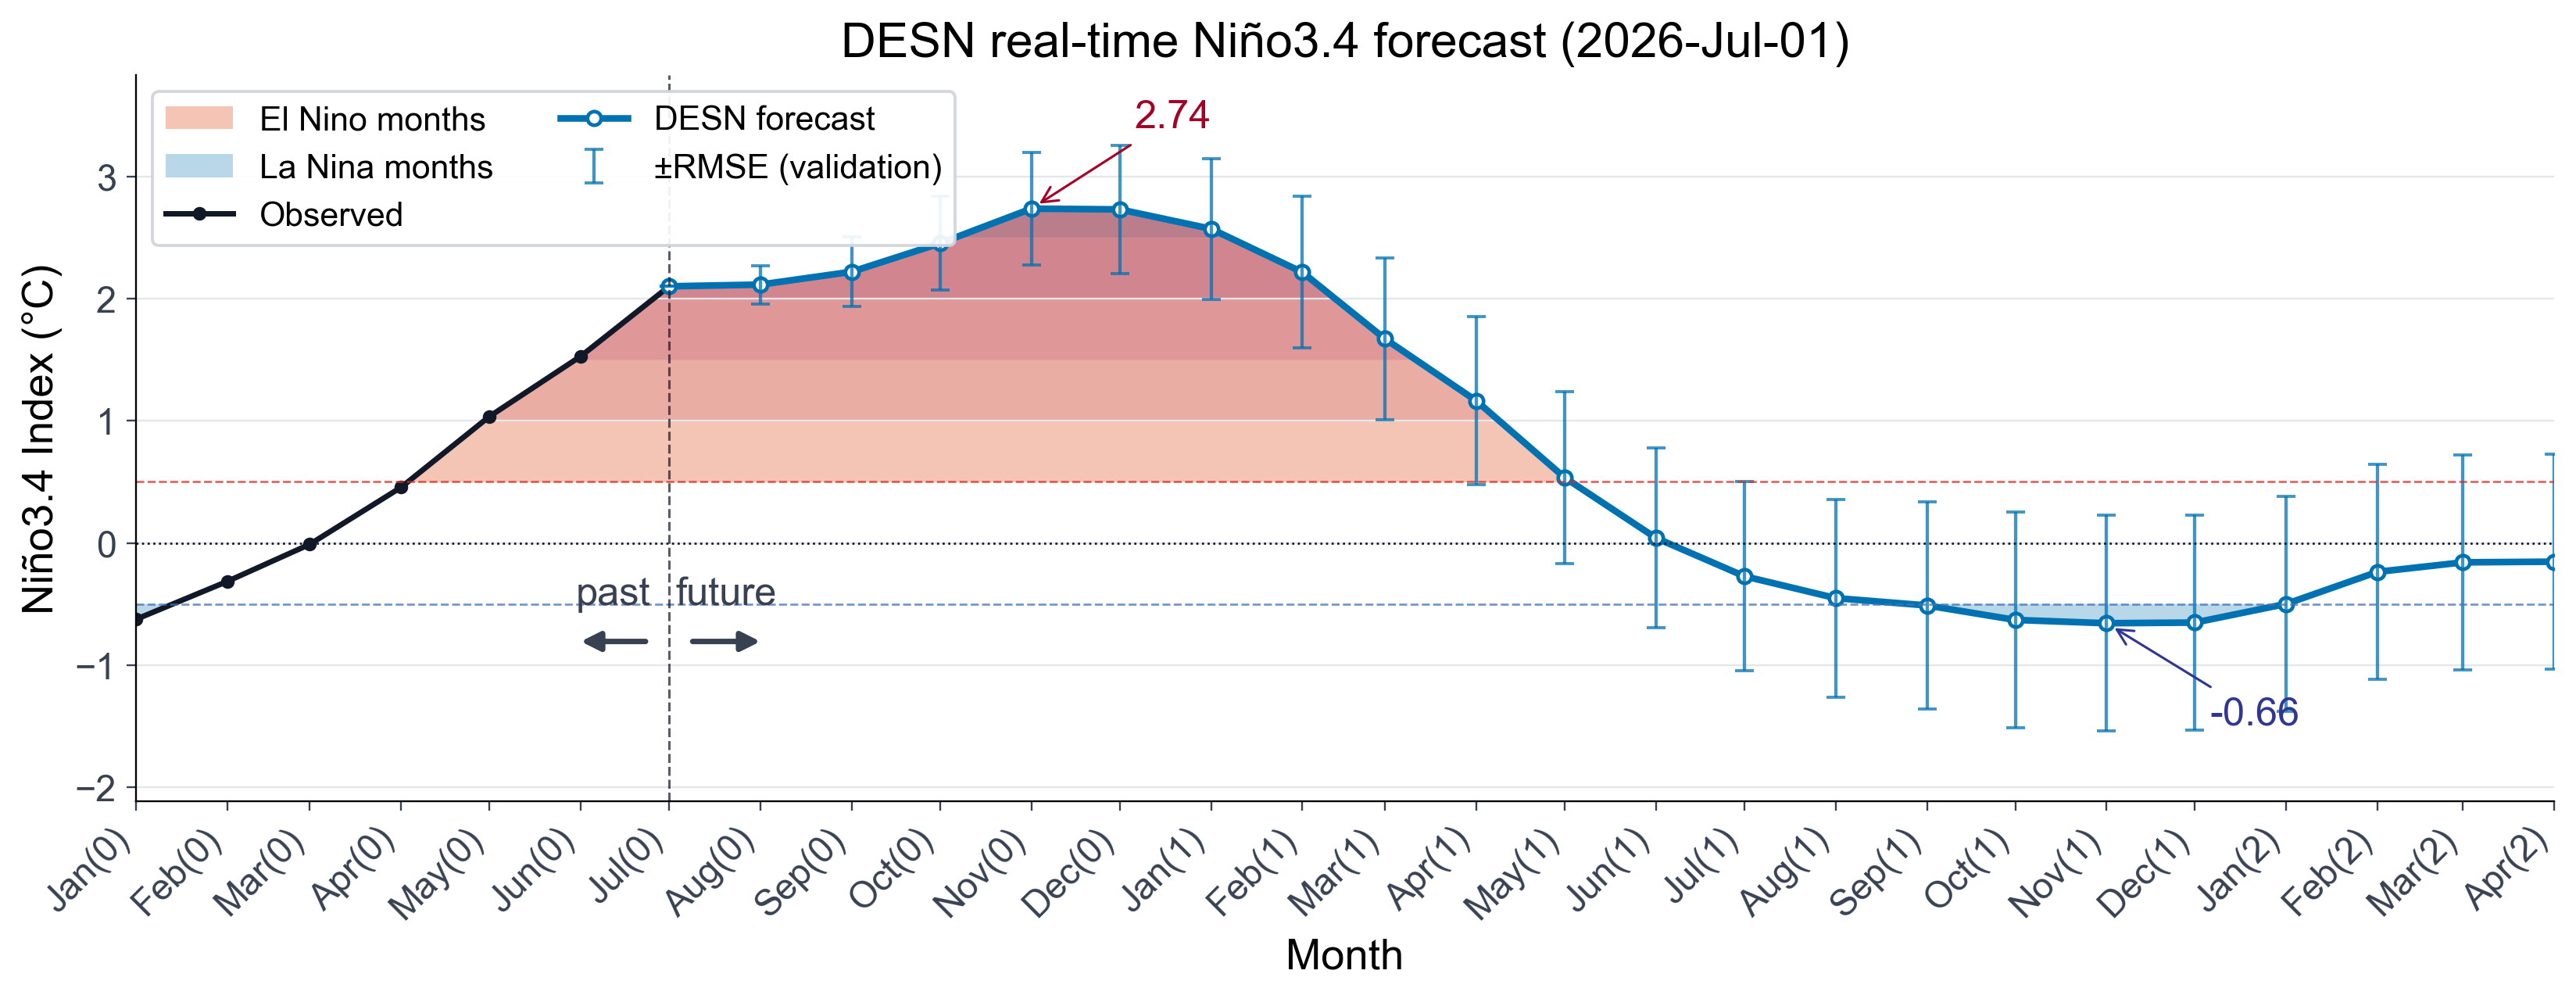

In [19]:
FIGURE_SAVE_DIR = FORECAST_DIR / f'desn_forecast_{REALTIME_START[:7]}'
FIGURE_SAVE_DIR.mkdir(parents=True, exist_ok=True)

main_title = f'DESN real-time Niño3.4 forecast ({date_label(REALTIME_START)})'
fig, ax = plot_realtime_forecast_styled(
    ds_full_to_latest, TS_full, rt_mean, forecast_times,
    REALTIME_START, mode_names, plot_mode=PLOT_MODE,
    history_months=PLOT_HISTORY_MONTHS, forecast_yerr=forecast_yerr,
    title=main_title)

figure_path = FIGURE_SAVE_DIR / f'desn_forecast_report_style_rmse_{REALTIME_START[:7]}.png'
fig.savefig(figure_path, dpi=300, bbox_inches='tight')
print(f'Saved report-style RMSE forecast figure -> {figure_path}')
plt.show()

In [20]:
# Peak value of the +RMSE validation upper envelope in the saved report-style figure
mode_idx = mode_names.index(PLOT_MODE)
forecast_center = np.asarray(rt_mean[:, mode_idx], dtype=float)
validation_rmse = np.asarray(forecast_yerr, dtype=float)
plus_rmse_curve = forecast_center + validation_rmse

peak_i = int(np.nanargmax(plus_rmse_curve))
peak_time = pd.Timestamp(forecast_times[peak_i])
peak_lead = peak_i

print('=== Peak of +RMSE (validation) in report-style forecast figure ===')
print(f'Figure: {figure_path}')
print(f'Mode: {PLOT_MODE}')
print(f'Peak month: {peak_time:%Y-%m}')
print(f'Lead month: {peak_lead}')
print(f'Forecast value at peak: {forecast_center[peak_i]:.3f}')
print(f'Validation RMSE at peak: {validation_rmse[peak_i]:.3f}')
print(f'+RMSE curve peak value: {plus_rmse_curve[peak_i]:.3f}')


=== Peak of +RMSE (validation) in report-style forecast figure ===
Figure: desn_forecast_2026-07\desn_forecast_report_style_rmse_2026-07.png
Mode: Nino34
Peak month: 2026-12
Lead month: 5
Forecast value at peak: 2.731
Validation RMSE at peak: 0.525
+RMSE curve peak value: 3.256


Saved validation RMSE figure -> desn_forecast_2026-07\desn_forecast_rmse_2026-07.png


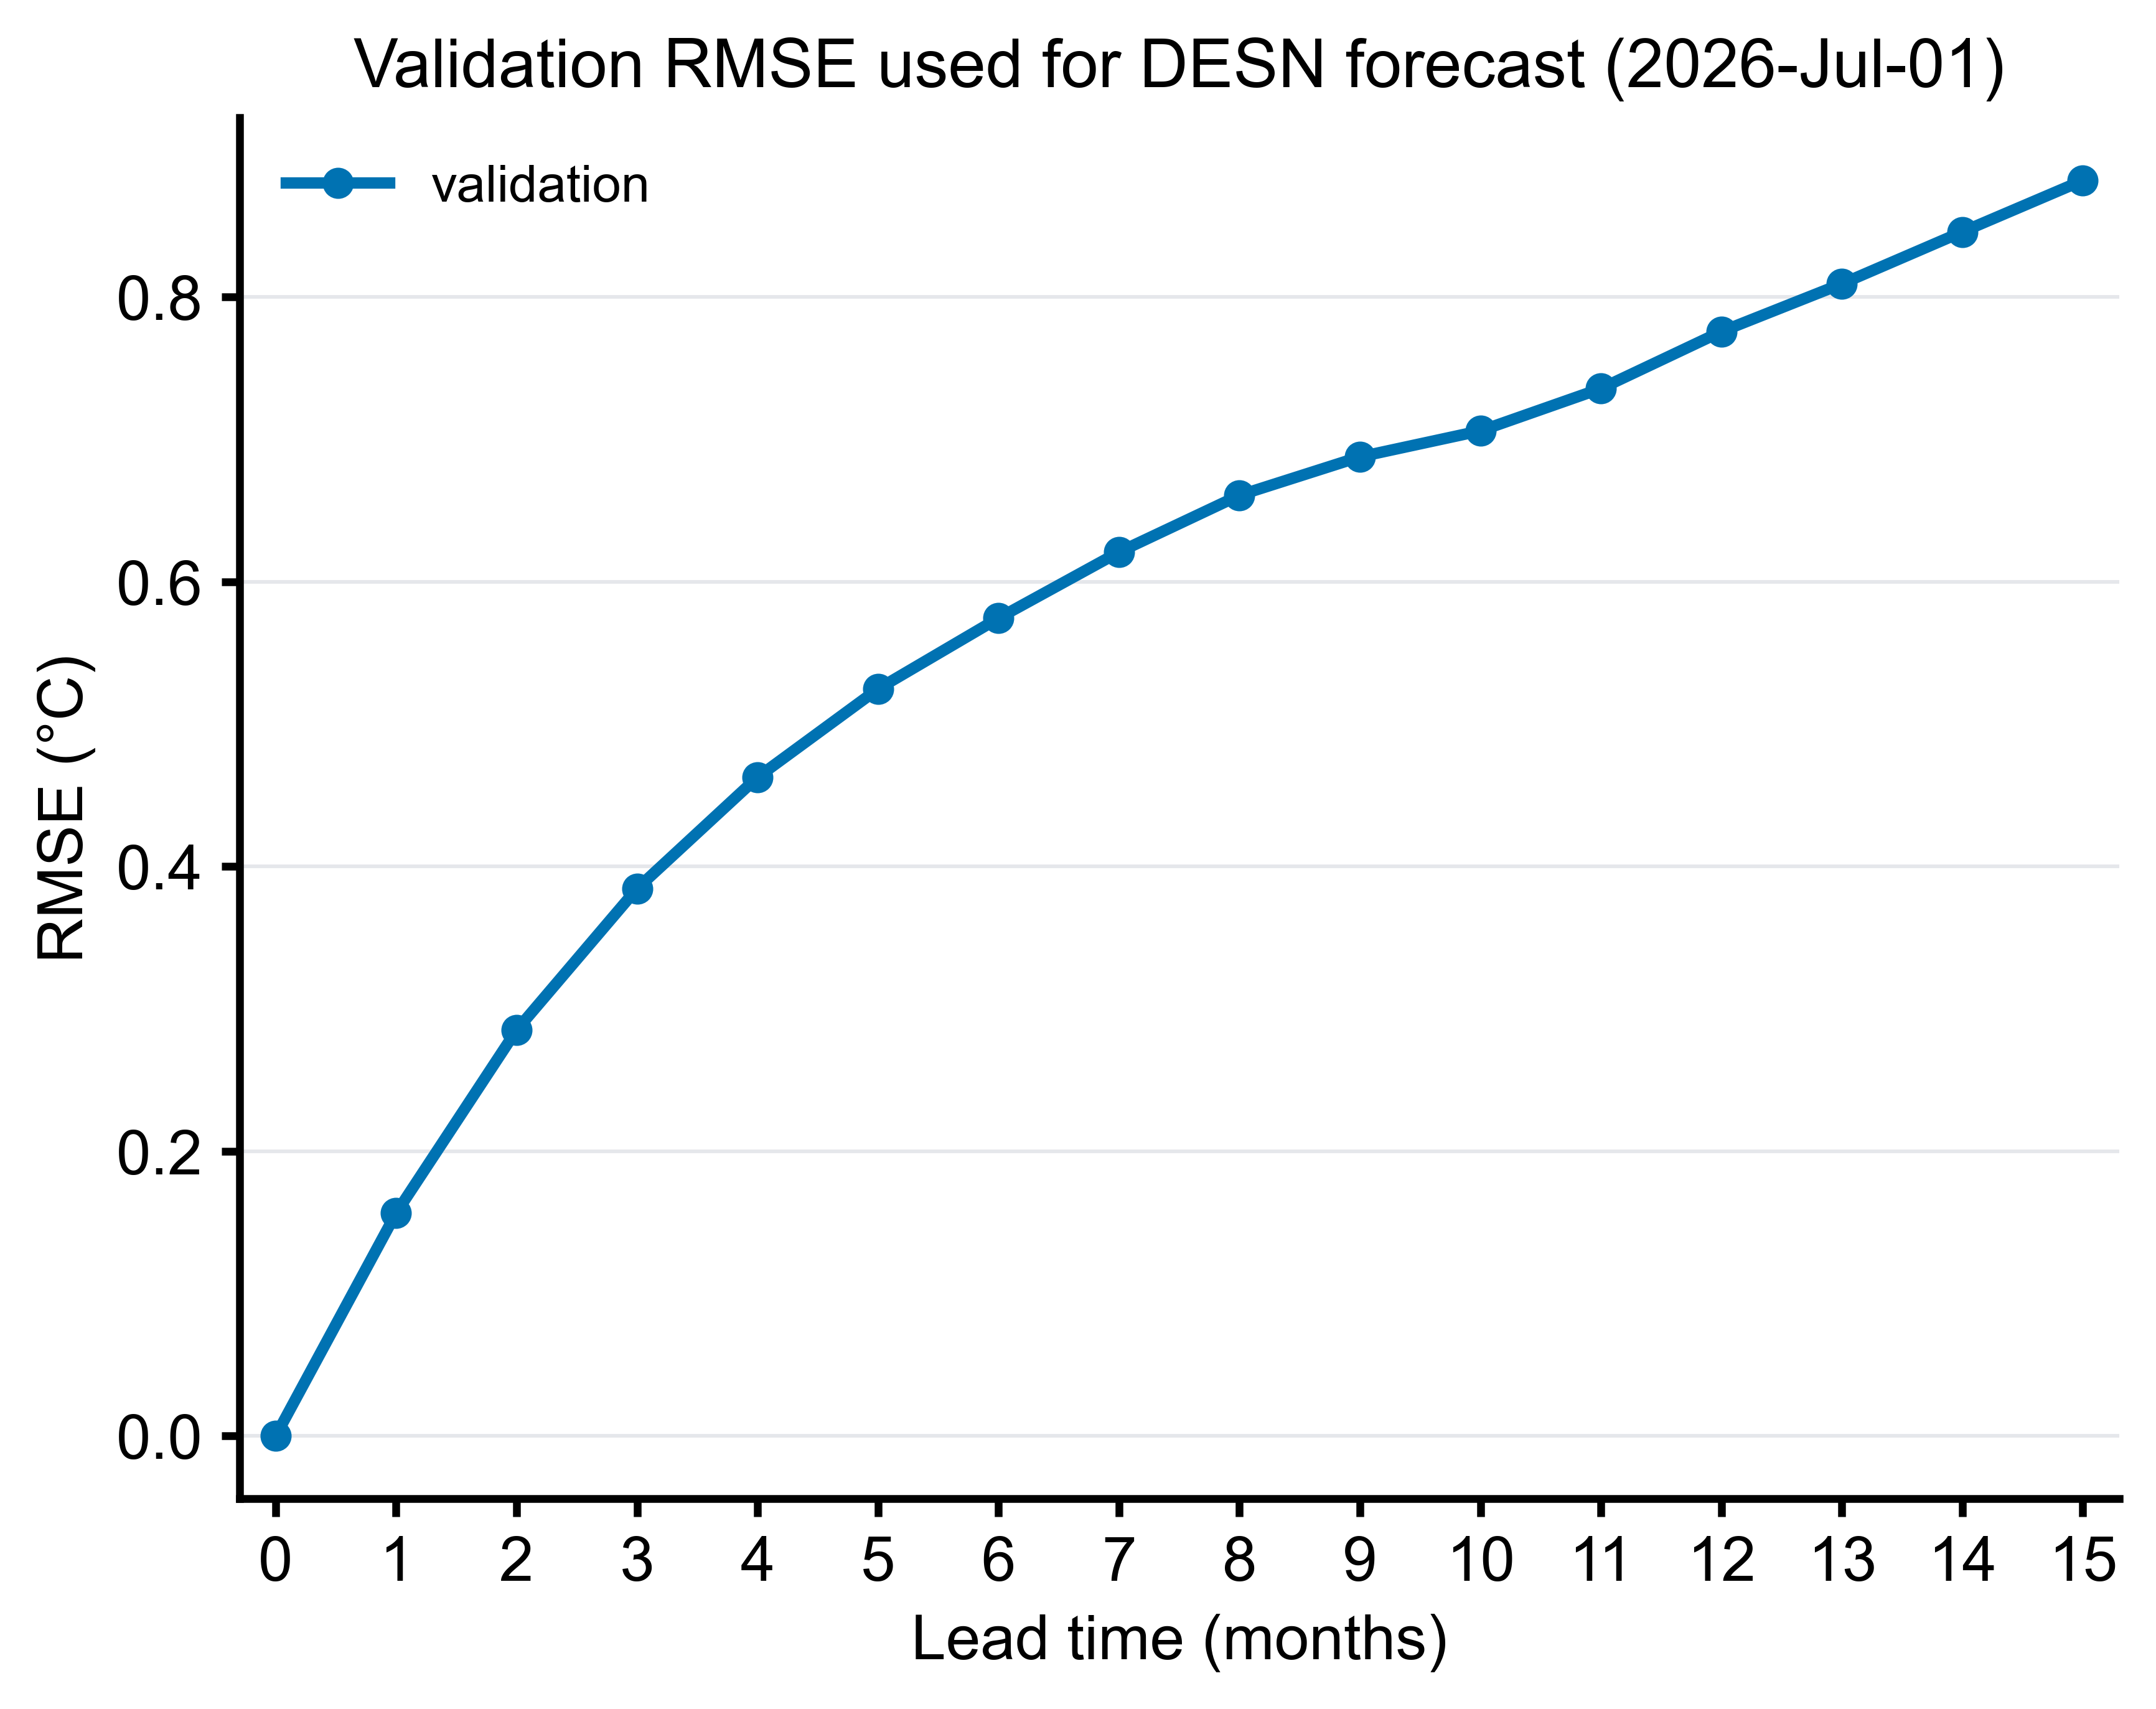

In [21]:
# Separate validation RMSE curve used by the report-style forecast figure
# This is the same forecast_yerr that appears as +RMSE / -RMSE error bars in the saved figure.
max_lead_to_plot = 15
lead_months_all = np.arange(len(forecast_yerr))
validation_rmse_all = np.asarray(forecast_yerr, dtype=float)
plot_mask = lead_months_all <= max_lead_to_plot
lead_months = lead_months_all[plot_mask]
validation_rmse_curve = validation_rmse_all[plot_mask]

fig_rmse, ax_rmse = plt.subplots(figsize=(6, 4.8), dpi=300)
ax_rmse.plot(lead_months, validation_rmse_curve, color="#0072B2",
             marker="o", linewidth=2.2, markersize=5.0, label="validation")

ax_rmse.set_title(f"Validation RMSE used for DESN forecast ({date_label(REALTIME_START)})", fontsize=13)
ax_rmse.set_xlabel("Lead time (months)", fontsize=12)
ax_rmse.set_ylabel("RMSE (°C)", fontsize=12)
ax_rmse.set_xticks(lead_months)
ax_rmse.set_xlim(lead_months[0] - 0.3, lead_months[-1] + 0.3)
ax_rmse.grid(axis="y", color="#e5e7eb", linewidth=0.7)
for spine in ["top", "right"]:
    ax_rmse.spines[spine].set_visible(False)
ax_rmse.legend(frameon=False, fontsize=10)
plt.tight_layout()

save_path = FIGURE_SAVE_DIR / f'desn_forecast_rmse_{REALTIME_START[:7]}.png'
FIGURE_SAVE_DIR.mkdir(parents=True, exist_ok=True)
fig_rmse.savefig(save_path, dpi=300, bbox_inches='tight')
print(f'Saved validation RMSE figure -> {save_path}')
plt.show()


Saved 3-month centered-mean RMSE forecast figure -> desn_forecast_2026-07\desn_forecast_report_style_rmse_mv3_2026-07.png
Centered forecast range: 2026-07 to 2028-03; raw forecast ends 2028-04.


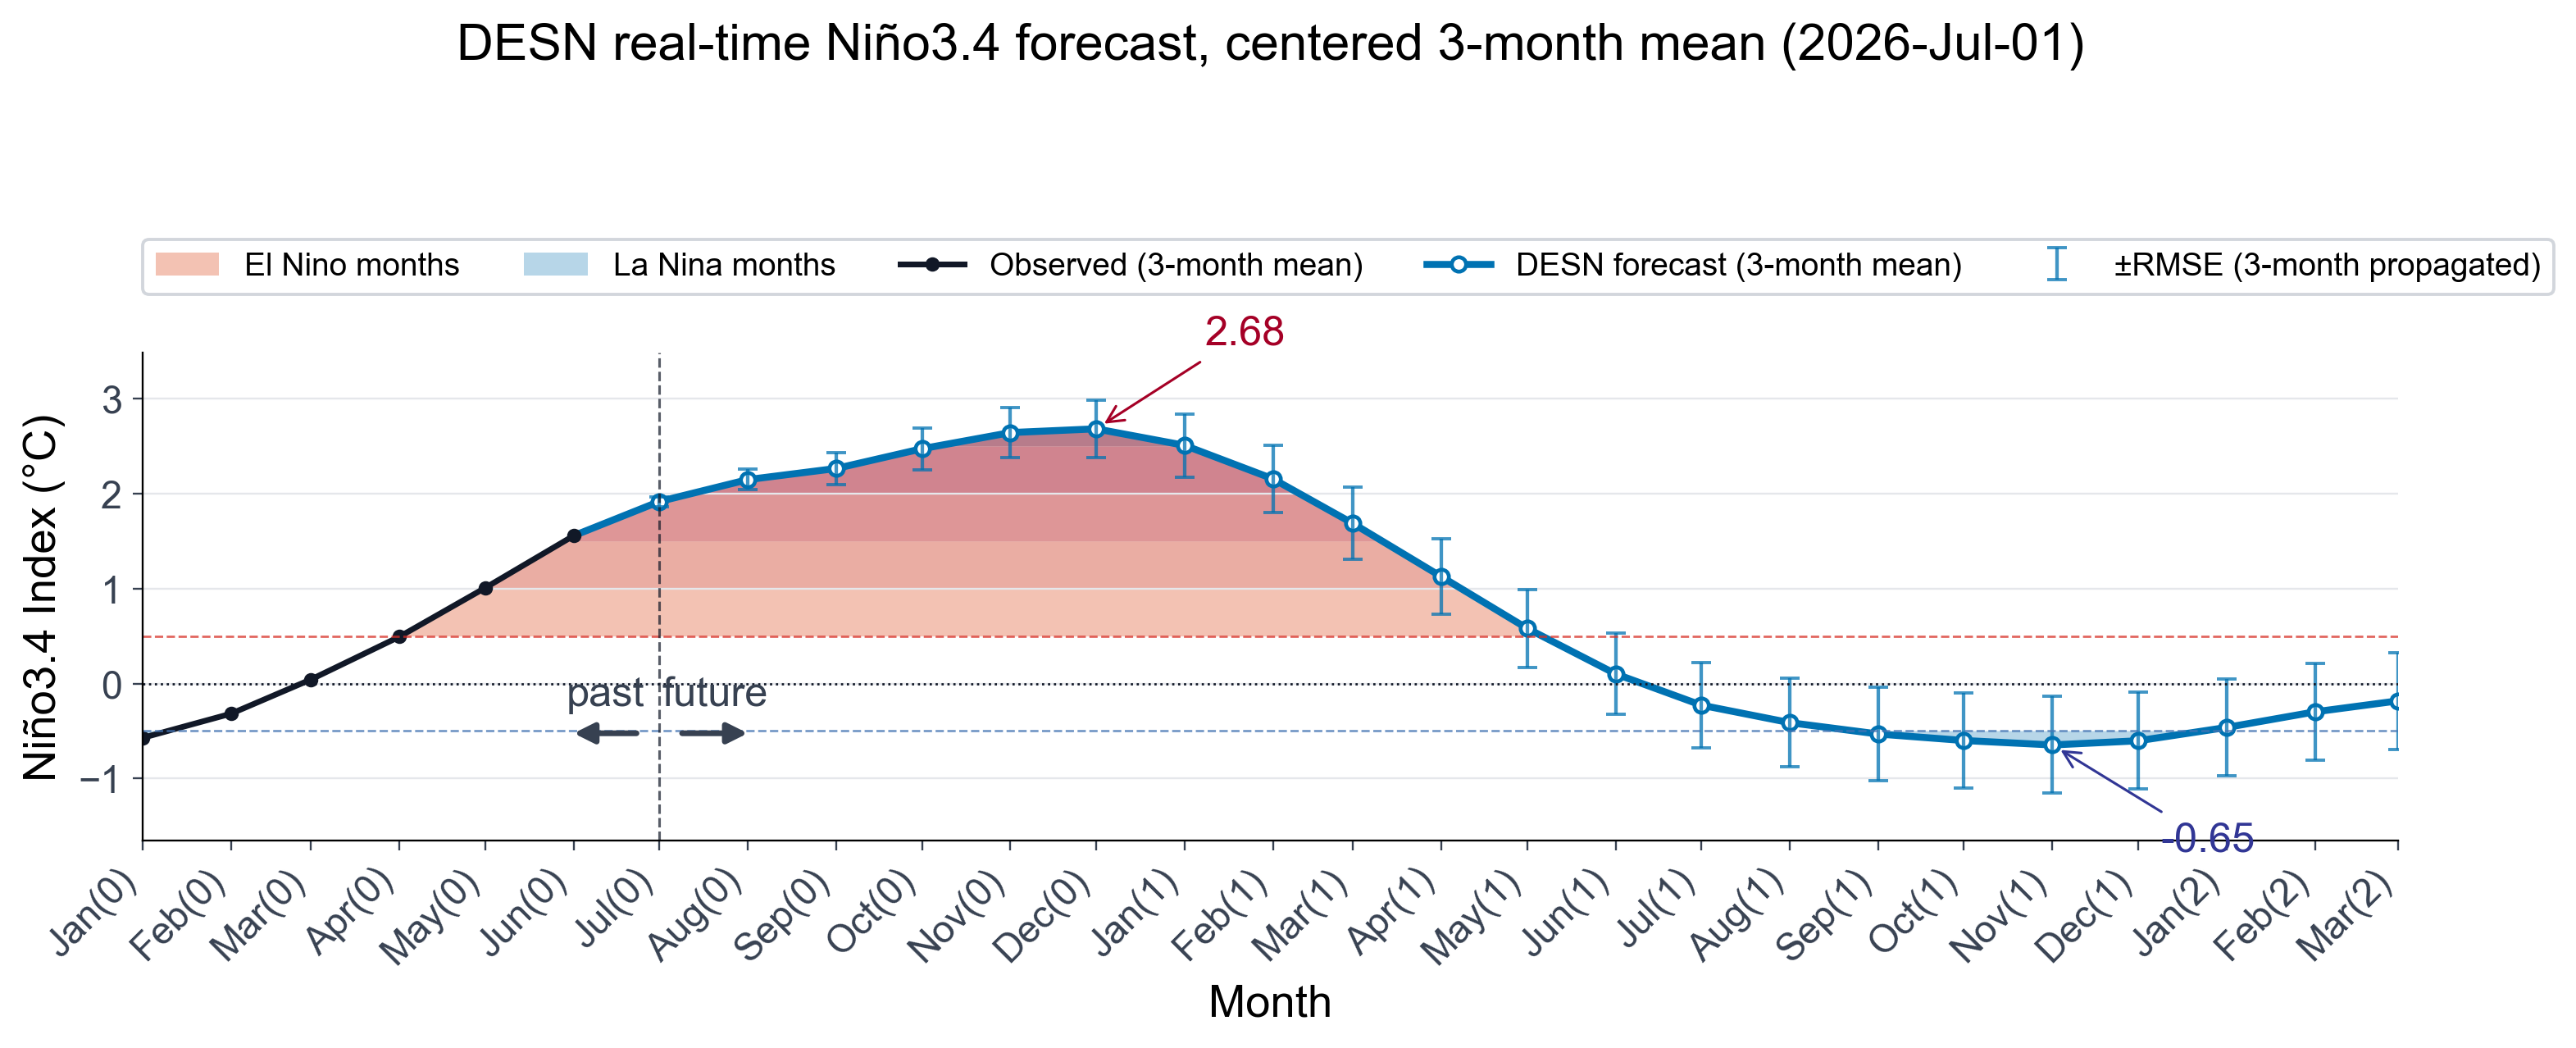

In [22]:
# Additional report-style figure: strict centered 3-month running mean
# The monthly forecast arrays and original report figure remain unchanged.

def centered_running_mean_3(values):
    """Return a strict centered 3-month mean with NaN at both edges."""
    values = np.asarray(values, dtype=float)
    if values.ndim != 1:
        raise ValueError('centered_running_mean_3 expects a one-dimensional series')
    result = np.full(values.shape, np.nan, dtype=float)
    if values.size >= 3:
        result[1:-1] = (values[:-2] + values[1:-1] + values[2:]) / 3.0
    return result


def centered_propagated_rmse_3(rmse):
    """Propagate three independent monthly RMSE values through their mean."""
    rmse = np.asarray(rmse, dtype=float)
    if rmse.ndim != 1:
        raise ValueError('centered_propagated_rmse_3 expects a one-dimensional series')
    result = np.full(rmse.shape, np.nan, dtype=float)
    if rmse.size >= 3:
        result[1:-1] = np.sqrt(
            rmse[:-2] ** 2 + rmse[1:-1] ** 2 + rmse[2:] ** 2
        ) / 3.0
    return result


# Deterministic checks for the smoothing and independent-error formulas.
np.testing.assert_allclose(
    centered_running_mean_3([1.0, 2.0, 4.0, 8.0, 16.0]),
    [np.nan, 7.0 / 3.0, 14.0 / 3.0, 28.0 / 3.0, np.nan],
    equal_nan=True,
)
np.testing.assert_allclose(
    centered_propagated_rmse_3([0.0, 0.0, 3.0, 4.0, 0.0]),
    [np.nan, 1.0, 5.0 / 3.0, 5.0 / 3.0, np.nan],
    equal_nan=True,
)

mv3_mode_idx = mode_names.index(PLOT_MODE)
mv3_base_month = to_month_start(REALTIME_START)
mv3_observed_times = pd.DatetimeIndex(pd.to_datetime(ds_full_to_latest.time.values))
mv3_observed_values = np.asarray(TS_full[:, mv3_mode_idx], dtype=float)

# ds_full_to_latest already contains the initialization month, so append
# forecast leads 1..N only. This makes the centered window continuous at
# the observed/forecast boundary without duplicating lead 0.
mv3_combined_times = mv3_observed_times.append(pd.DatetimeIndex(forecast_times[1:]))
mv3_combined_values = np.concatenate([
    mv3_observed_values,
    np.asarray(rt_mean[1:, mv3_mode_idx], dtype=float),
])
mv3_combined_rmse = np.concatenate([
    np.zeros(mv3_observed_values.size, dtype=float),
    np.asarray(forecast_yerr[1:], dtype=float),
])

mv3_expected_times = pd.date_range(
    mv3_combined_times[0], mv3_combined_times[-1], freq='MS'
)
if not mv3_combined_times.equals(mv3_expected_times):
    raise ValueError('Observed and forecast inputs must form one continuous monthly series')

mv3_all_values = centered_running_mean_3(mv3_combined_values)
mv3_all_rmse = centered_propagated_rmse_3(mv3_combined_rmse)
mv3_valid = np.isfinite(mv3_all_values) & np.isfinite(mv3_all_rmse)
mv3_times = mv3_combined_times[mv3_valid]
mv3_values = mv3_all_values[mv3_valid]
mv3_rmse = mv3_all_rmse[mv3_valid]

mv3_visible_start = mv3_base_month - pd.DateOffset(months=PLOT_HISTORY_MONTHS)
mv3_visible = mv3_times >= mv3_visible_start
mv3_plot_times = mv3_times[mv3_visible]
mv3_plot_values = mv3_values[mv3_visible]
mv3_plot_rmse = mv3_rmse[mv3_visible]
mv3_observed_mask = mv3_plot_times < mv3_base_month
mv3_forecast_mask = mv3_plot_times >= mv3_base_month

if not np.any(mv3_observed_mask) or not np.any(mv3_forecast_mask):
    raise ValueError('Centered 3-month plot needs both observed and forecast months')

mv3_transition_indices = np.array([
    np.flatnonzero(mv3_observed_mask)[-1],
    np.flatnonzero(mv3_forecast_mask)[0],
], dtype=int)
if mv3_transition_indices[1] - mv3_transition_indices[0] != 1:
    raise ValueError('Observed and forecast plot segments must be adjacent')
if not (
    mv3_plot_times[mv3_transition_indices[0]] < mv3_base_month
    <= mv3_plot_times[mv3_transition_indices[1]]
):
    raise ValueError('Transition segment must cross the initialization month')

mv3_fig, mv3_ax = plt.subplots(figsize=(12, 4.8), dpi=140)
shade_enso_lanina(mv3_ax, mv3_plot_times, mv3_plot_values)

# Bridge the final observation to the first forecast without changing
# either point's classification, marker, or uncertainty.
mv3_ax.plot(
    mv3_plot_times[mv3_transition_indices],
    mv3_plot_values[mv3_transition_indices],
    color='#0072B2', linewidth=2.2, marker=None, label='_nolegend_',
)
mv3_ax.plot(
    mv3_plot_times[mv3_observed_mask], mv3_plot_values[mv3_observed_mask],
    color='#111827', linewidth=1.8, marker='o', markersize=3.5,
    label='Observed (3-month mean)',
)
mv3_ax.plot(
    mv3_plot_times[mv3_forecast_mask], mv3_plot_values[mv3_forecast_mask],
    color='#0072B2', linewidth=2.2, marker='o', markersize=4.5,
    markerfacecolor='white', markeredgewidth=1.2,
    label='DESN forecast (3-month mean)',
)
mv3_ax.errorbar(
    mv3_plot_times[mv3_forecast_mask], mv3_plot_values[mv3_forecast_mask],
    yerr=mv3_plot_rmse[mv3_forecast_mask], fmt='none',
    ecolor='#0072B2', elinewidth=1.1, capsize=3, alpha=0.75,
    label='±RMSE (3-month propagated)',
)

mv3_ax.axhline(0, color='#111827', linewidth=0.7, linestyle=':')
mv3_ax.axhline(0.5, color='#d73027', linewidth=0.7, linestyle='--', alpha=0.75)
mv3_ax.axhline(-0.5, color='#4575b4', linewidth=0.7, linestyle='--', alpha=0.75)
mv3_ax.axvline(mv3_base_month, color='#111827', linewidth=0.8, linestyle='--', alpha=0.7)

mv3_forecast_values = mv3_plot_values[mv3_forecast_mask]
mv3_forecast_rmse = mv3_plot_rmse[mv3_forecast_mask]
mv3_y_values = np.concatenate([
    mv3_plot_values,
    mv3_forecast_values - mv3_forecast_rmse,
    mv3_forecast_values + mv3_forecast_rmse,
])
mv3_ymin, mv3_ymax = np.nanmin(mv3_y_values), np.nanmax(mv3_y_values)
mv3_y_pad = max(0.25, 0.12 * (mv3_ymax - mv3_ymin if mv3_ymax > mv3_ymin else 1.0))
mv3_ax.set_ylim(mv3_ymin - mv3_y_pad, mv3_ymax + mv3_y_pad)
add_past_future_arrows(
    mv3_ax, mv3_base_month, mv3_ymin - mv3_y_pad, mv3_ymax + mv3_y_pad
)

annotate_extreme(
    mv3_ax, mv3_plot_times, mv3_plot_values, mv3_plot_values >= 0.5,
    np.argmax, '#a50026', 'above',
)
annotate_extreme(
    mv3_ax, mv3_plot_times, mv3_plot_values, mv3_plot_values <= -0.5,
    np.argmin, '#313695', 'below',
)

mv3_tick_times = pd.date_range(mv3_plot_times[0], mv3_plot_times[-1], freq='MS')
mv3_ax.set_xticks(mv3_tick_times)
mv3_ax.set_xticklabels(
    [month_year_label(ts, mv3_base_month) for ts in mv3_tick_times],
    rotation=45, ha='right', fontsize=12,
)
mv3_ax.set_title(
    f'DESN real-time Niño3.4 forecast, centered 3-month mean ({date_label(REALTIME_START)})',
    fontsize=16, pad=92,
)
mv3_ax.set_ylabel('Niño3.4 Index (°C)', fontsize=14)
mv3_ax.set_xlabel('Month', fontsize=14)
mv3_ax.set_xlim(mv3_plot_times[0], mv3_plot_times[-1])
for mv3_spine in ['top', 'right']:
    mv3_ax.spines[mv3_spine].set_visible(False)
for mv3_spine in ['left', 'bottom']:
    mv3_ax.spines[mv3_spine].set_linewidth(0.6)
mv3_ax.tick_params(axis='both', width=0.6, length=3, colors='#374151', labelsize=12)
mv3_ax.grid(axis='y', color='#e5e7eb', linewidth=0.6)
mv3_ax.legend(
    loc='lower left', bbox_to_anchor=(0.0, 1.12), borderaxespad=0.0,
    frameon=True, facecolor='white', edgecolor='#d1d5db',
    framealpha=0.96, ncol=5, fontsize=10.0,
)
plt.tight_layout()

FIGURE_SAVE_DIR.mkdir(parents=True, exist_ok=True)
mv3_figure_path = (
    FIGURE_SAVE_DIR
    / f'desn_forecast_report_style_rmse_mv3_{REALTIME_START[:7]}.png'
)
mv3_fig.savefig(mv3_figure_path, dpi=300, bbox_inches='tight')
print(f'Saved 3-month centered-mean RMSE forecast figure -> {mv3_figure_path}')
print(
    f'Centered forecast range: {mv3_plot_times[mv3_forecast_mask][0]:%Y-%m} to '
    f'{mv3_plot_times[mv3_forecast_mask][-1]:%Y-%m}; '
    f'raw forecast ends {pd.Timestamp(forecast_times[-1]):%Y-%m}.'
)
plt.show()
